# Aptidão para lançamento de foguete por lógica fuzzy (Mamdani, malha aberta)

## 1. Identificação e declaração de uso de IA

| Campo | Conteúdo |
| --- | --- |
| Nome | Caio Vasconcelos |
| Disciplina | Inteligência Artificial e Bioinspirada |
| Ferramenta de IA utilizada | Claude |
| Finalidade do uso | Planejamento da estrutura do trabalho e geração de código base |
| Extensão aproximada da contribuição | Apoio no planejamento do projeto e no código boilerplate |
| Medidas de validação do conteúdo | Abertura e conferência das fontes citadas, execução do código, conferência das conversões de unidade e comparação dos resultados dos testes com o comportamento esperado |

## 2. Instruções de execução

Requisitos: Python 3.12 ou mais recente (as versões fixadas de numpy, scipy e networkx exigem 3.12; o notebook foi testado com Python 3.14.5). Na raiz do repositório:

```
pip install -r requirements.txt
jupyter notebook notebook/lancamento_fuzzy.ipynb
```

Depois, no Jupyter, use **Kernel > Restart Kernel and Run All Cells…**. O notebook roda do início ao fim sem nenhum passo manual. Os dados de referência são lidos da pasta `data/` da raiz do repositório (arquivos `criterios_referencia.csv` e `casos_reais.csv`). Como o notebook fica na pasta `notebook/`, o código a acessa pelo caminho relativo `../data`.

A célula da validação A avalia 68.921 combinações de entradas e é a mais demorada (menos de meio minuto, porque avalia muitos pontos de uma vez, em modo vetorizado). O tempo exato é impresso pela própria célula.

Para executar sem abrir o navegador:

```
jupyter nbconvert --to notebook --execute --inplace notebook/lancamento_fuzzy.ipynb
```

## 3. Introdução e problema

**Problema.** Antes de cada lançamento, uma equipe de meteorologia avalia se o clima permite lançar ("go") ou não ("no-go"). Os critérios oficiais são limites rígidos, como "não lançar com vento acima de 30 mph".

**Objetivo.** Construir um sistema fuzzy, em malha aberta, que traduza esses critérios em uma **aptidão gradual de 0 a 100%**, com três decisões: **Abortar**, **Aguardar** e **Lançar**. As entradas são o vento (km/h), a distância da tempestade (km) e a temperatura (°C).

**Relevância.** O clima é a principal causa de adiamentos. Segundo a [RocketLaunch.Live](https://www.rocketlaunch.live/scrub-statistics), 72 dos 123 adiamentos com causa registrada desde 2017 (59%, em consulta de novembro de 2026) foram por clima. O acidente do Challenger, em 1986, mostrou o custo de lançar fora das condições seguras.

**Por que lógica fuzzy.** Perto de um limite, o risco cresce aos poucos. Um vento de 45 km/h não é tão seguro quanto um de 10 km/h, embora os dois estejam abaixo do limite de 48 km/h. A lógica fuzzy, criada a partir da teoria dos conjuntos fuzzy (ZADEH, 1965), representa essa graduação com termos linguísticos (fraco, moderado, forte), do mesmo jeito que um especialista raciocina.

**Malha aberta.** O sistema só dá uma recomendação. A saída não volta para alterar as entradas: é um sistema de apoio à decisão, e não um controlador.

### Hipóteses do modelo

- O sistema usa só três fatores do clima. Nuvens, precipitação e vento em altitude ficam de fora.
- Os limites vêm de critérios publicados pela NASA (Falcon 9, Artemis I e ônibus espacial) e, no caso do Atlas V, divulgados pelo Spaceflight Now. Cada foguete real tem limites próprios.
- "Duas condições de atenção ao mesmo tempo" levam a Abortar. É uma postura conservadora, declarada como hipótese.
- Calor acima de 35 °C é condição de atenção (Aguardar), e não crítica. O limite de 95 °F do Artemis vale só para levar o foguete à plataforma. No ônibus espacial, depois de iniciado o abastecimento, a contagem só parava se a temperatura passasse de 99 °F (37 °C) por mais de 30 minutos seguidos ([NASA – Shuttle Weather Launch Commit Criteria](https://www3.nasa.gov/centers/kennedy/pdf/633165main_weather-rules-march2011.pdf)). Já o frio aborta sozinho, pelo precedente do Challenger.
- A entrada de vento é o vento sustentado. As fontes medem o vento em alturas diferentes (60 pés no Challenger e 162 pés no critério do Falcon 9; nas previsões dos casos reais, o vento é o da plataforma ou do solo, sem altura informada), e as rajadas ficam de fora. As duas coisas entram como limitação.

### Glossário

| Termo | Significado neste trabalho |
| --- | --- |
| **Crisp** | Valor "nítido", um número comum, como 45 km/h. Também se chama crisp a regra de sim/não, do tipo "acima de 48,3 km/h não lança". |
| **Grau de pertinência** | Número entre 0 e 1 que diz o quanto um valor crisp pertence a um termo. Um vento de 45 km/h é 0,33 "Moderado" e 0,33 "Forte" ao mesmo tempo. |
| **Universo** | Conjunto de valores possíveis de uma variável, como 0 a 80 km/h para o vento. |
| **Função de pertinência** | Curva que dá, para cada valor do universo, o grau de pertinência a um termo. Aqui ela é triangular ou trapezoidal. |
| **Termo linguístico** | Rótulo de um conjunto fuzzy, como "Fraco", "Perto" ou "Amena". Cada termo tem uma função de pertinência (triangular ou trapezoidal). |
| **Regra** | Frase do tipo SE vento é Fraco E tempestade é Longe E temperatura é Amena ENTÃO aptidão é Lançar. A **força** da regra é o quanto a parte SE é verdadeira (o mínimo dos graus). |
| **Antecedente e consequente** | As partes SE e ENTÃO de uma regra. O antecedente combina as entradas; o consequente é o termo da saída. |
| **Fuzzificação** | Transformar um valor crisp de entrada em graus de pertinência a cada termo. |
| **Implicação** | Cortar o conjunto de saída de uma regra na altura da sua força (pelo mínimo). |
| **Agregação** | Junção, pelo máximo, das saídas de todas as regras ativadas, formando uma única figura sobre o eixo de 0 a 100%. |
| **Defuzzificação** | Transformar a figura agregada de volta num número crisp. Aqui ela é feita pelo centroide. |
| **Centroide** | "Centro de gravidade" da figura agregada. É o número crisp final, a aptidão em %. |
| **Go/no-go** | Decisão binária de lançar (go) ou não lançar (no-go), usada pelas equipes reais de lançamento. |

## 4. Fontes e dados de referência

Os limites oficiais que fundamentam as funções de pertinência (e que definem o critério crisp da validação A) e os casos reais da validação B vêm de dois arquivos CSV na pasta `data/` da raiz do repositório (UTF-8 com BOM, separador vírgula, decimal com ponto). Os pontos das funções de pertinência foram escolhidos a partir desses limites, como explicado na seção 5.

- `criterios_referencia.csv`: os limites oficiais de clima para lançamento, com o valor original, o valor convertido para o SI, a fonte e o papel de cada um no modelo.
- `casos_reais.csv`: os três estudos de caso da validação B.

A célula abaixo importa as bibliotecas, define as cores dos gráficos e lê os dois arquivos. Como os endereços das fontes e as observações são longos, cada tabela é exibida sem essas colunas, e os links completos e clicáveis (e, nos casos reais, as observações) aparecem logo abaixo dela. A codificação `utf-8-sig` remove o BOM do início do arquivo. O BOM é uma marca invisível que ajuda o Excel a reconhecer a codificação UTF-8; sem removê-lo, o nome da primeira coluna sairia errado.

In [1]:
import itertools
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from IPython.display import Markdown, display
import warnings
# API interna do scikit-fuzzy 0.5.0 (a mesma que o método .view(sim=...) usa) para obter a figura agregada
from skfuzzy.control.controlsystem import CrispValueCalculator

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

# Cores: termos de entrada em ordem fixa (azul, laranja, verde-água); saída com as cores de estado
# (vermelho = Abortar, amarelo = Aguardar, verde = Lançar), sempre acompanhadas de legenda.
COR_TERMOS = ['#2a78d6', '#eb6834', '#1baf7a']
COR_SAIDA = {'Abortar': '#d03b3b', 'Aguardar': '#fab219', 'Lançar': '#0ca30c'}
COR_TEXTO = '#0b0b0b'
MAPA_APTIDAO = LinearSegmentedColormap.from_list(
    'aptidao_azul', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
plt.rcParams.update({
    'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'lines.linewidth': 2, 'font.size': 10,
})

PASTA_DADOS = Path('../data')
criterios = pd.read_csv(PASTA_DADOS / 'criterios_referencia.csv', encoding='utf-8-sig')
casos = pd.read_csv(PASTA_DADOS / 'casos_reais.csv', encoding='utf-8-sig')
print(f'scikit-fuzzy {fuzz.__version__}, numpy {np.__version__}, pandas {pd.__version__}')

def mostrar_com_fontes(tabela):
    """Mostra a tabela sem as colunas longas e, logo abaixo, os links completos e clicáveis e as observações."""
    longas = [c for c in ('link', 'observacoes') if c in tabela.columns]
    display(tabela.drop(columns=longas))
    fontes = tabela[['fonte', 'link']].drop_duplicates()
    # uma fonte pode ter mais de um link, separados por ' | '
    linhas = [f'- {f}: ' + ' e '.join(f'<{u.strip()}>' for u in links.split('|')) for f, links in fontes.itertuples(index=False)]
    texto = '**Links das fontes:**\n\n' + '\n'.join(linhas)
    if 'observacoes' in tabela.columns:
        texto += '\n\n**Observações:**\n\n' + '\n'.join(f'- **{c}:** {o}' for c, o in zip(tabela.iloc[:, 0], tabela.observacoes))
    display(Markdown(texto))

mostrar_com_fontes(criterios)

scikit-fuzzy 0.5.0, numpy 2.5.4, pandas 3.1.1


,variavel,criterio,valor_original,unidade_original,valor_convertido,unidade_si,fonte,uso_no_modelo
0,vento,Máximo sustentado a 162 pés da plataforma (Falcon 9 Crew Dragon),30,mph,48.3,km/h,NASA – Falcon 9 Crew Dragon Launch Weather Criteria,Transição Moderado → Forte
1,vento,Máximo para lançar (primeiro Atlas V),30,nós,55.6,km/h,Spaceflight Now – Launch commit criteria for first Atlas 5,Topo do termo Forte
2,tempestade,Não lançar por 30 min após raio a menos desta distância,10,milhas náuticas,18.5,km,NASA – Falcon 9 Crew Dragon Launch Weather Criteria,Limite do termo Perto
3,temperatura,Mínima para levar o foguete à plataforma (Artemis I),40,°F,4.4,°C,NASA – Artemis I Weather Criteria,Limite do termo Fria
4,temperatura,Máxima para levar o foguete à plataforma (Artemis I),95,°F,35.0,°C,NASA – Artemis I Weather Criteria,Limite do termo Quente
5,temperatura,"Após o início do abastecimento, a contagem do ônibus espacial não continua acima deste valor por mais de 30 min",99,°F,37.2,°C,NASA – Space Shuttle Weather Launch Commit Criteria (2011),"Justifica Quente como atenção, e não crítico"
6,temperatura,Temperatura no lançamento do Challenger (STS-51-L),36,°F,2.2,°C,"NASA – Report of the Presidential Commission on the Space Shuttle Challenger Accident, cap. III",Núcleo do termo Fria e caso de teste


**Links das fontes:**

- NASA – Falcon 9 Crew Dragon Launch Weather Criteria: <https://www.nasa.gov/wp-content/uploads/2021/07/falcon9_crewdragon_launch_weather_criteria_fact_sheet.pdf>
- Spaceflight Now – Launch commit criteria for first Atlas 5: <https://spaceflightnow.com/atlas/av001/020817weather/>
- NASA – Artemis I Weather Criteria: <https://www.nasa.gov/directorates/esdmd/common-exploration-systems-development-division/orion-program/artemis-i-weather-criteria/>
- NASA – Space Shuttle Weather Launch Commit Criteria (2011): <https://www3.nasa.gov/centers/kennedy/pdf/633165main_weather-rules-march2011.pdf>
- NASA – Report of the Presidential Commission on the Space Shuttle Challenger Accident, cap. III: <https://www.nasa.gov/history/rogersrep/v1ch3.htm>

A tabela acima tem os sete critérios de referência. Cada linha traz o valor como aparece na fonte (mph, nós, milhas náuticas ou °F), o valor convertido para km/h, km ou °C e o uso no modelo: por exemplo, o vento máximo de 30 mph do Falcon 9 (48,3 km/h) marca a transição do vento Moderado para o Forte.

A célula seguinte refaz as conversões de unidade com os fatores de conversão usuais (1 mph = 1,609 km/h; 1 nó = 1,852 km/h; 1 milha náutica = 1,852 km; °C = (°F − 32) / 1,8) e confere, com um `assert` (comando que interrompe o notebook com erro se a condição for falsa), se batem com a coluna `valor_convertido`, com tolerância de 0,1 (o CSV guarda uma casa decimal).

In [2]:
CONVERSOES = {
    'mph': lambda x: x * 1.609,
    'nós': lambda x: x * 1.852,
    'milhas náuticas': lambda x: x * 1.852,
    '°F': lambda x: (x - 32) / 1.8,
}
conferencia = criterios[['variavel', 'valor_original', 'unidade_original', 'valor_convertido', 'unidade_si']].copy()
conferencia['recalculado'] = [CONVERSOES[u](v) for u, v in zip(criterios.unidade_original, criterios.valor_original)]
conferencia['diferenca'] = (conferencia.recalculado - conferencia.valor_convertido).abs()
assert (conferencia.diferenca <= 0.1).all(), 'Alguma conversão do CSV não bate com os fatores de conversão'
print('Todas as conversões do CSV conferem (diferença máxima = %.3f).' % conferencia.diferenca.max())
conferencia.round(3)

Todas as conversões do CSV conferem (diferença máxima = 0.044).


,variavel,valor_original,unidade_original,valor_convertido,unidade_si,recalculado,diferenca
0,vento,30,mph,48.3,km/h,48.270,0.030
1,vento,30,nós,55.6,km/h,55.560,0.040
2,tempestade,10,milhas náuticas,18.5,km,18.520,0.020
3,temperatura,40,°F,4.4,°C,4.444,0.044
4,temperatura,95,°F,35.0,°C,35.000,0.000
5,temperatura,99,°F,37.2,°C,37.222,0.022
6,temperatura,36,°F,2.2,°C,2.222,0.022


Todas as conversões conferem: a maior diferença entre o valor recalculado e o valor do CSV vem só do arredondamento para uma casa decimal.

Agora, os casos reais. O vento de cada caso é dado como uma faixa de vento sustentado (`vento_kmh_min` a `vento_kmh_max`). O modelo usa o **ponto médio** da faixa. A rajada (`rajada_kmh`) fica só como registro e não entra no modelo. A coluna `observacoes`, listada abaixo da tabela, diz o que foi medido e o que foi estimado. Na tabela, `NaN` significa "valor não informado": nenhuma das fontes informa rajadas, então essa coluna fica vazia.

In [3]:
mostrar_com_fontes(casos)

,caso,data,foguete,vento_kmh_min,vento_kmh_max,rajada_kmh,dist_tempestade_km,temp_c,referencia_real,fonte
0,Challenger,1986-01-28,Space Shuttle Challenger (STS-51-L),22.0,22.0,NaN,50.0,2.2,Lançou; desintegrou-se aos 73 s,"NASA TM-86577 (vento, céu, raios); Relatório da Comissão Rogers, cap. III (temperatura)"
1,Dia bom,2023-02-27,Falcon 9 (NASA SpaceX Crew-6),0.0,8.0,NaN,50.0,18.3,5% de chance de violar os critérios,NASA – Commercial Crew blog (previsão do 45th Weather Squadron); FOX 35 Orlando (vento e temperatura)
2,Dia ruim,2004-08-29,"Atlas 2AS (AC-167, NROL-1)",18.5,18.5,NaN,9.3,29.4,60% de chance de violar os critérios,Spaceflight Now – previsão do 45th Weather Squadron


**Links das fontes:**

- NASA TM-86577 (vento, céu, raios); Relatório da Comissão Rogers, cap. III (temperatura): <https://ntrs.nasa.gov/citations/19870009517> e <https://www.nasa.gov/history/rogersrep/v1ch3.htm>
- NASA – Commercial Crew blog (previsão do 45th Weather Squadron); FOX 35 Orlando (vento e temperatura): <https://www.nasa.gov/blogs/commercialcrew/2023/02/27/weather-looking-great-for-nasas-spacex-crew-6-launch/> e <https://www.fox35orlando.com/news/crew-6-launch-forecast-will-florida-skies-stay-clear-for-liftoff>
- Spaceflight Now – previsão do 45th Weather Squadron: <https://spaceflightnow.com/atlas/ac167/040829wx.html>

**Observações:**

- **Challenger:** Medição: vento de 11,9 nós a 60 pés, de norte-noroeste. Céu limpo, sem chuva nem raios: tempestade = 50 (sem tempestade). Temperatura de 36 °F medida a cerca de 1.000 pés da plataforma (Comissão Rogers, cap. III). Rajadas não informadas.
- **Dia bom:** Previsão, não medição, para a tentativa de 27/02/2023 às 1:45 EST. NASA: 95% de chance de tempo favorável (45th Weather Squadron), com a regra de nuvens cumulus como principal preocupação. FOX 35: vento no solo de calmo a 5 mph (0–8 km/h) e cerca de 65 °F no horário do lançamento, sem menção a chuva ou tempestades: tempestade = 50 (sem tempestade). Rajadas não informadas.
- **Dia ruim:** Previsão emitida em 28/08/2004 para o lançamento de 29/08/2004. Vento na plataforma de noroeste (300°), 10 nós (18,5 km/h); rajadas não informadas. Tempestades isoladas a até 10 milhas náuticas (18,5 km) do complexo: distância estimada pelo ponto médio, cerca de 9,3 km. Temperatura de 85 °F. A previsão para o adiamento de 24 h também era de 60%.

São três casos: o Challenger (1986, medição: lançou com frio e se desintegrou), um "dia bom" do Falcon 9 da missão Crew-6 da NASA (2023, previsão de 5% de chance de violar os critérios) e um "dia ruim" do Atlas 2AS AC-167 (2004, previsão de 60% de chance de violar os critérios, com tempestades isoladas). No Crew-6, a probabilidade vem do blog da NASA, e o vento e a temperatura vêm da previsão da FOX 35, de Orlando. A distância de 9,3 km do Atlas é uma estimativa: a previsão só diz "tempestades isoladas a até 10 milhas náuticas" (18,5 km) do complexo, e foi usado o ponto médio dessa faixa. Esses casos são usados na seção 10.

## 5. Modelagem das variáveis

São três entradas e uma saída, cada uma com três termos linguísticos. Os pontos de cada função de pertinência estão na tabela abaixo e são justificados depois dos gráficos. Os universos (os valores possíveis de cada variável) são discretizados com passo de 0,5 nas entradas e de 1 na saída.

| Variável | Tipo | Domínio | Termo | Função | Pontos | Papel na decisão |
| --- | --- | --- | --- | --- | --- | --- |
| Vento | Entrada | 0–80 km/h | Fraco | Trapezoidal | 0, 0, 15, 30 | Favorável |
| Vento | Entrada | 0–80 km/h | Moderado | Triangular | 20, 35, 50 | Atenção |
| Vento | Entrada | 0–80 km/h | Forte | Trapezoidal | 40, 55, 80, 80 | Crítico |
| Distância da tempestade | Entrada | 0–50 km (50 = sem tempestade) | Perto | Trapezoidal | 0, 0, 12, 20 | Crítico |
| Distância da tempestade | Entrada | 0–50 km | Média | Triangular | 15, 25, 35 | Atenção |
| Distância da tempestade | Entrada | 0–50 km | Longe | Trapezoidal | 30, 40, 50, 50 | Favorável |
| Temperatura | Entrada | −10 a 45 °C | Fria | Trapezoidal | −10, −10, 2, 8 | Crítico |
| Temperatura | Entrada | −10 a 45 °C | Amena | Trapezoidal | 4, 10, 26, 33 | Favorável |
| Temperatura | Entrada | −10 a 45 °C | Quente | Trapezoidal | 30, 36, 45, 45 | Atenção |
| Aptidão | Saída | 0–100% | Abortar | Trapezoidal | 0, 0, 20, 40 | — |
| Aptidão | Saída | 0–100% | Aguardar | Triangular | 30, 50, 70 | — |
| Aptidão | Saída | 0–100% | Lançar | Trapezoidal | 60, 80, 100, 100 | — |

Uma função **triangular** `[a, b, c]` vale 0 em `a`, sobe até 1 em `b` e desce até 0 em `c`. Uma **trapezoidal** `[a, b, c, d]` sobe de 0 a 1 entre `a` e `b`, fica em 1 entre `b` e `c` e desce até 0 entre `c` e `d`. Quando `a = b` (ou `c = d`), o trapézio começa (ou termina) já em 1, o que serve para os extremos do domínio.

A célula abaixo cria as variáveis com `skfuzzy.control`: `Antecedent` para as entradas e `Consequent` para a saída, que já recebe a defuzzificação por centroide.

In [4]:
vento = ctrl.Antecedent(np.arange(0, 80 + 0.5, 0.5), 'vento')
tempestade = ctrl.Antecedent(np.arange(0, 50 + 0.5, 0.5), 'tempestade')
temperatura = ctrl.Antecedent(np.arange(-10, 45 + 0.5, 0.5), 'temperatura')
aptidao = ctrl.Consequent(np.arange(0, 100 + 1, 1), 'aptidao', defuzzify_method='centroid')

vento['Fraco'] = fuzz.trapmf(vento.universe, [0, 0, 15, 30])
vento['Moderado'] = fuzz.trimf(vento.universe, [20, 35, 50])
vento['Forte'] = fuzz.trapmf(vento.universe, [40, 55, 80, 80])

tempestade['Perto'] = fuzz.trapmf(tempestade.universe, [0, 0, 12, 20])
tempestade['Média'] = fuzz.trimf(tempestade.universe, [15, 25, 35])
tempestade['Longe'] = fuzz.trapmf(tempestade.universe, [30, 40, 50, 50])

temperatura['Fria'] = fuzz.trapmf(temperatura.universe, [-10, -10, 2, 8])
temperatura['Amena'] = fuzz.trapmf(temperatura.universe, [4, 10, 26, 33])
temperatura['Quente'] = fuzz.trapmf(temperatura.universe, [30, 36, 45, 45])

aptidao['Abortar'] = fuzz.trapmf(aptidao.universe, [0, 0, 20, 40])
aptidao['Aguardar'] = fuzz.trimf(aptidao.universe, [30, 50, 70])
aptidao['Lançar'] = fuzz.trapmf(aptidao.universe, [60, 80, 100, 100])

VARIAVEIS = [vento, tempestade, temperatura, aptidao]
for var in VARIAVEIS:
    u = var.universe
    print(f'{var.label:12s} universo {u.min():6.1f} a {u.max():6.1f}, passo {u[1] - u[0]}, {len(u)} pontos, termos: {list(var.terms)}')

vento        universo    0.0 a   80.0, passo 0.5, 161 pontos, termos: ['Fraco', 'Moderado', 'Forte']
tempestade   universo    0.0 a   50.0, passo 0.5, 101 pontos, termos: ['Perto', 'Média', 'Longe']
temperatura  universo  -10.0 a   45.0, passo 0.5, 111 pontos, termos: ['Fria', 'Amena', 'Quente']
aptidao      universo    0.0 a  100.0, passo 1, 101 pontos, termos: ['Abortar', 'Aguardar', 'Lançar']


Os quatro universos foram criados com os domínios e passos definidos acima. A próxima célula desenha as funções de pertinência. Em cada gráfico, o eixo horizontal é o valor crisp da variável, e o vertical, o grau de pertinência (0 a 1). As linhas verticais pontilhadas marcam os valores de referência lidos do CSV de critérios (os limites oficiais e, na temperatura, também os 2,2 °C do Challenger).

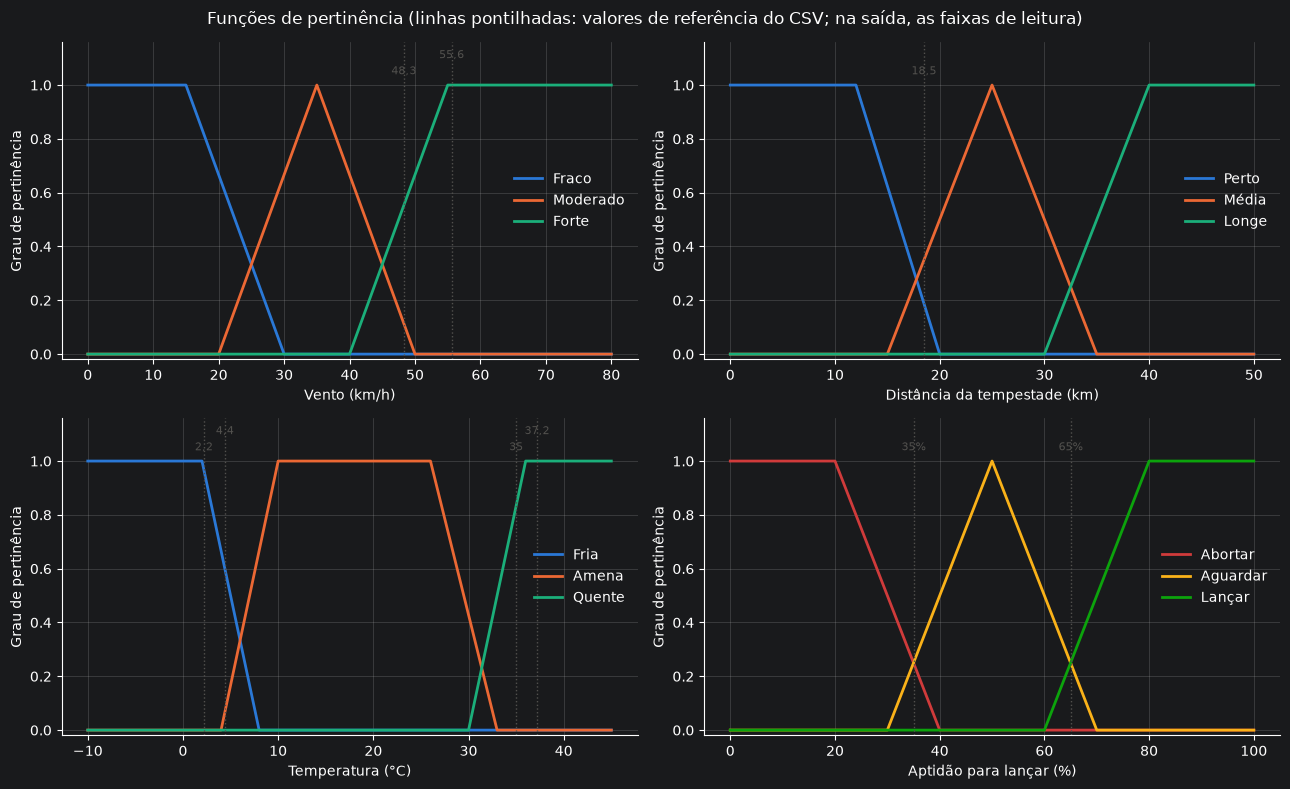

In [5]:
def limites_csv(variavel):
    sel = criterios[criterios.variavel == variavel]
    return list(zip(sel.valor_convertido, sel.criterio))

UNIDADES = {'vento': 'Vento (km/h)', 'tempestade': 'Distância da tempestade (km)',
            'temperatura': 'Temperatura (°C)', 'aptidao': 'Aptidão para lançar (%)'}

fig, eixos = plt.subplots(2, 2, figsize=(13, 8))
for ax, var in zip(eixos.flat, VARIAVEIS):
    for i, termo in enumerate(var.terms):
        cor = COR_SAIDA[termo] if var is aptidao else COR_TERMOS[i]
        ax.plot(var.universe, var[termo].mf, color=cor, label=termo)
    if var is not aptidao:
        # rótulos alternam de altura para não se sobrepor quando dois valores são próximos
        for j, (valor, _) in enumerate(sorted(limites_csv(var.label))):
            ax.axvline(valor, color='#52514e', linestyle=':', linewidth=1)
            ax.text(valor, 1.04 if j % 2 == 0 else 1.10, f'{valor:g}'.replace('.', ','), ha='center', fontsize=8, color='#52514e')
    else:
        for x in (35, 65):
            ax.axvline(x, color='#52514e', linestyle=':', linewidth=1)
            ax.text(x, 1.04, f'{x}%', ha='center', fontsize=8, color='#52514e')
    ax.set_xlabel(UNIDADES[var.label])
    ax.set_ylabel('Grau de pertinência')
    ax.set_ylim(-0.02, 1.16)
    ax.legend(loc='center right', frameon=False)
fig.suptitle('Funções de pertinência (linhas pontilhadas: valores de referência do CSV; na saída, as faixas de leitura)')
fig.tight_layout()
plt.show()

**Como ler os gráficos.** Para saber o grau de um valor em cada termo, sobe-se uma linha vertical a partir do valor e lê-se a altura em que ela corta cada curva.

- **Vento:** o termo Fraco é total até 15 km/h. O Moderado tem o ponto típico em 35 km/h. A transição Moderado → Forte cruza em 45 km/h (grau 0,33 em cada um), logo abaixo do limite de 48,3 km/h do Falcon 9. A partir de 55 km/h (perto do limite de 55,6 km/h do Atlas V), o vento é totalmente Forte.
- **Tempestade:** até 12 km a tempestade está totalmente Perto. Perto e Média se cruzam em cerca de 17,8 km, perto do limite de 18,5 km da regra de raios. De 40 km em diante a tempestade está totalmente Longe; 50 km representa "sem tempestade".
- **Temperatura:** Fria é total até 2 °C (o Challenger) e cruza com Amena em 6 °C, perto do limite de 4,4 °C. Quente começa em 30 °C e é total a partir de 36 °C, logo acima do limite de 35 °C. O ponto de 37,2 °C (limite do ônibus espacial depois de iniciado o abastecimento) já cai em Quente total. Como esse limite só parava a contagem depois de 30 minutos seguidos de calor, o calor foi tratado como atenção, e não como condição crítica (ver as hipóteses na seção 3).
- **Trapezoidais nas pontas**, porque os extremos do domínio são totalmente bons ou ruins. **Triangulares no meio**, porque o termo de atenção tem um ponto típico.
- **Saída:** os três termos se sobrepõem entre 30 e 40 e entre 60 e 70, o que gera transições suaves no centroide. As linhas em 35% e 65% são as faixas de leitura: abaixo de 35%, Abortar; de 35% a 65%, Aguardar; acima de 65%, Lançar.

A célula abaixo confere no código os pontos de cruzamento citados acima, procurando no universo onde os dois termos vizinhos têm o mesmo grau.

In [6]:
def cruzamento(var, termo_a, termo_b, entre):
    """Primeiro ponto de uma grade fina, dentro do intervalo 'entre', em que o termo_b passa a ser >= termo_a."""
    u = var.universe
    x_fino = np.linspace(*entre, 20001)
    a = fuzz.interp_membership(u, var[termo_a].mf, x_fino)
    b = fuzz.interp_membership(u, var[termo_b].mf, x_fino)
    assert (b >= a).any(), f'{termo_a} e {termo_b} não se cruzam em {entre}'
    i = np.argmax(b >= a)
    return x_fino[i], a[i]

for var, ta, tb, faixa in [(vento, 'Moderado', 'Forte', (40, 50)), (tempestade, 'Perto', 'Média', (15, 20)),
                           (temperatura, 'Fria', 'Amena', (4, 8)), (temperatura, 'Amena', 'Quente', (30, 33))]:
    x, g = cruzamento(var, ta, tb, faixa)
    print(f'{var.label:11s}: {ta} x {tb} cruzam em {x:.2f} com grau {g:.3f}')

vento      : Moderado x Forte cruzam em 45.00 com grau 0.333
tempestade : Perto x Média cruzam em 17.78 com grau 0.278
temperatura: Fria x Amena cruzam em 6.00 com grau 0.333
temperatura: Amena x Quente cruzam em 31.38 com grau 0.231


Os cruzamentos calculados confirmam as justificativas: vento em 45 km/h, tempestade em cerca de 17,8 km e temperatura Fria × Amena em 6 °C. O cruzamento Amena × Quente fica em cerca de 31,4 °C.

### Cobertura do domínio

Um valor de entrada sem pertinência em nenhum termo não ativaria nenhuma regra, e o sistema não teria resposta. É preciso que, em cada variável, todo valor tenha pertinência maior que zero em pelo menos um termo. Isso acontece porque os termos vizinhos se sobrepõem (vento 20–30 e 40–50 km/h; tempestade 15–20 e 30–35 km; temperatura 4–8 e 30–33 °C). A célula abaixo confere isso em todos os pontos de cada universo, inclusive na saída.

In [7]:
for var in VARIAVEIS:
    graus = np.vstack([var[t].mf for t in var.terms])
    pior = graus.max(axis=0).min()
    assert pior > 0, f'{var.label}: existe valor sem pertinência em nenhum termo'
    print(f'{var.label:12s}: menor "maior grau" no universo = {pior:.3f} (> 0, cobertura completa)')

vento       : menor "maior grau" no universo = 0.333 (> 0, cobertura completa)
tempestade  : menor "maior grau" no universo = 0.250 (> 0, cobertura completa)
temperatura : menor "maior grau" no universo = 0.250 (> 0, cobertura completa)
aptidao     : menor "maior grau" no universo = 0.250 (> 0, cobertura completa)


Em todas as variáveis, o pior ponto do universo ainda pertence a algum termo com grau positivo. Nas entradas, esse pior ponto fica no meio de uma zona de sobreposição: por exemplo, em 45 km/h o vento é 0,33 Moderado e 0,33 Forte. A cobertura do domínio está garantida.

## 6. Base de regras

A base tem 27 regras, uma para cada combinação de termos (3 × 3 × 3). Por isso ela é **completa**: qualquer combinação de entradas ativa pelo menos uma regra.

**Lógica usada para gerar as regras:**

1. Qualquer termo **crítico** (vento Forte, tempestade Perto, temperatura Fria) → **Abortar**.
2. Sem termo crítico, contam-se os termos de **atenção** (vento Moderado, tempestade Média, temperatura Quente):
   - nenhum → **Lançar**;
   - um → **Aguardar**;
   - dois ou mais → **Abortar**.

Origem: os termos críticos traduzem os critérios oficiais da seção 4 (`criterios_referencia.csv`). A regra das duas condições de atenção é uma hipótese conservadora do autor.

A célula abaixo gera as 27 regras com essa lógica e confere, com um `assert` (comando que interrompe o notebook com erro se a condição for falsa), que o resultado é idêntico a uma **tabela de conferência**: as mesmas 27 regras digitadas uma a uma no código, com antecedentes e consequente. Como as duas formas foram montadas de jeitos independentes, um erro na lógica ou na digitação seria detectado.

In [8]:
TERMOS_VENTO = ['Fraco', 'Moderado', 'Forte']
TERMOS_TEMPESTADE = ['Longe', 'Média', 'Perto']
TERMOS_TEMPERATURA = ['Amena', 'Quente', 'Fria']
CRITICOS = {'Forte', 'Perto', 'Fria'}
ATENCAO = {'Moderado', 'Média', 'Quente'}

def consequente(combinacao):
    if CRITICOS & set(combinacao):
        return 'Abortar'
    n_atencao = len(ATENCAO & set(combinacao))
    return 'Lançar' if n_atencao == 0 else ('Aguardar' if n_atencao == 1 else 'Abortar')

combinacoes = list(itertools.product(TERMOS_VENTO, TERMOS_TEMPESTADE, TERMOS_TEMPERATURA))
regras_df = pd.DataFrame(
    [(i, v, s, t, consequente((v, s, t))) for i, (v, s, t) in enumerate(combinacoes, start=1)],
    columns=['#', 'Vento', 'Tempestade', 'Temperatura', 'Aptidão']).set_index('#')

# Tabela de conferência, com as 27 regras digitadas uma a uma: (vento, tempestade, temperatura, aptidão), regras 1 a 27
TABELA_CONFERENCIA = [
    ('Fraco', 'Longe', 'Amena', 'Lançar'), ('Fraco', 'Longe', 'Quente', 'Aguardar'), ('Fraco', 'Longe', 'Fria', 'Abortar'),
    ('Fraco', 'Média', 'Amena', 'Aguardar'), ('Fraco', 'Média', 'Quente', 'Abortar'), ('Fraco', 'Média', 'Fria', 'Abortar'),
    ('Fraco', 'Perto', 'Amena', 'Abortar'), ('Fraco', 'Perto', 'Quente', 'Abortar'), ('Fraco', 'Perto', 'Fria', 'Abortar'),
    ('Moderado', 'Longe', 'Amena', 'Aguardar'), ('Moderado', 'Longe', 'Quente', 'Abortar'), ('Moderado', 'Longe', 'Fria', 'Abortar'),
    ('Moderado', 'Média', 'Amena', 'Abortar'), ('Moderado', 'Média', 'Quente', 'Abortar'), ('Moderado', 'Média', 'Fria', 'Abortar'),
    ('Moderado', 'Perto', 'Amena', 'Abortar'), ('Moderado', 'Perto', 'Quente', 'Abortar'), ('Moderado', 'Perto', 'Fria', 'Abortar'),
    ('Forte', 'Longe', 'Amena', 'Abortar'), ('Forte', 'Longe', 'Quente', 'Abortar'), ('Forte', 'Longe', 'Fria', 'Abortar'),
    ('Forte', 'Média', 'Amena', 'Abortar'), ('Forte', 'Média', 'Quente', 'Abortar'), ('Forte', 'Média', 'Fria', 'Abortar'),
    ('Forte', 'Perto', 'Amena', 'Abortar'), ('Forte', 'Perto', 'Quente', 'Abortar'), ('Forte', 'Perto', 'Fria', 'Abortar'),
]
assert len(regras_df) == 27
assert list(regras_df.itertuples(index=False, name=None)) == TABELA_CONFERENCIA, 'As regras geradas não batem com a tabela de conferência'
print('As 27 regras geradas são idênticas às da tabela de conferência.')
print(regras_df['Aptidão'].value_counts().to_string())
regras_df

As 27 regras geradas são idênticas às da tabela de conferência.
Aptidão
Abortar     23
Aguardar     3
Lançar       1


,Vento,Tempestade,Temperatura,Aptidão
#,,,,
1,Fraco,Longe,Amena,Lançar
2,Fraco,Longe,Quente,Aguardar
3,Fraco,Longe,Fria,Abortar
4,Fraco,Média,Amena,Aguardar
5,Fraco,Média,Quente,Abortar
6,Fraco,Média,Fria,Abortar
7,Fraco,Perto,Amena,Abortar
8,Fraco,Perto,Quente,Abortar
9,Fraco,Perto,Fria,Abortar


As 27 regras geradas pela lógica são idênticas às da tabela de conferência. A contagem mostra um **aspecto importante**: 23 regras levam a Abortar, 3 a Aguardar (regras 2, 4 e 10, cada uma com uma única condição de atenção) e só 1 a Lançar (regra 1, tudo favorável). Isso reflete a postura conservadora de segurança. A graduação da saída vem das funções de pertinência nas zonas de transição, onde duas ou mais regras ficam ativas ao mesmo tempo.

## 7. Implementação Mamdani e justificativa

O sistema usa inferência **Mamdani** (MAMDANI; ASSILIAN, 1975), porque a saída também é linguística (Abortar, Aguardar, Lançar) e cada passo do cálculo pode ser mostrado em gráfico.

**Passo a passo do cálculo:**

1. **Fuzzificação:** cada entrada crisp vira graus de pertinência. Um vento de 45 km/h, por exemplo, é 0,33 Moderado e 0,33 Forte.
2. **Avaliação das regras:** o "E" entre os antecedentes usa o **mínimo** dos graus. Essa é a força da regra.
3. **Implicação:** cada regra corta o seu conjunto de saída na altura da sua força (**mínimo**).
4. **Agregação:** os conjuntos cortados se juntam pelo **máximo**.
5. **Defuzzificação:** o **centroide** da forma agregada é a aptidão crisp.

**Leitura da saída:** abaixo de 35% → Abortar; de 35% a 65% → Aguardar; acima de 65% → Lançar.

**Limite do centroide:** a saída nunca chega a 0% nem a 100%. Com só Abortar ativo (força 1), o centroide fica em cerca de 16%; com só Lançar, em cerca de 84%. Isso é esperado no Mamdani com centroide (ROSS, 2016): o piso é o centro de gravidade do trapézio de Abortar inteiro, e qualquer corte abaixo de 1 só desloca esse centro para a direita (como no teste 2); pela simetria, o teto é o centro do trapézio de Lançar inteiro.

**Por que não Takagi–Sugeno:** o Sugeno (TAKAGI; SUGENO, 1985) usa constantes ou funções na saída e é mais rápido, o que importa em controle em tempo real. Ele também evitaria a compressão da escala entre 15,56% e 84,44%, mas perderia a saída linguística. Aqui o sistema é de apoio à decisão, em malha aberta, e a interpretação pesa mais que a velocidade.

**No scikit-fuzzy:** `ctrl.Rule` usa, por padrão, o mínimo para o "E" e o corte (mínimo) para a implicação, e o `ControlSystem` agrega pelo máximo. A defuzzificação foi declarada como `centroid` no `Consequent`. A opção `clip_to_bounds=True` da simulação limita as entradas fora do domínio ao extremo mais próximo (uma tempestade a 80 km entra como 50 km). Na simulação usada para avaliar uma entrada por vez, o *cache* do scikit-fuzzy (a memória de resultados já calculados) foi desligado (`cache=False`), porque cada entrada só é calculada uma vez e guardar o estado de todas só gastaria memória. Com o cache desligado, porém, o scikit-fuzzy apaga a força das regras logo depois de cada cálculo; com ele ligado, apaga tudo a cada 1.000 cálculos. Por isso, quando é preciso saber quais regras ativaram, `avaliar` cria uma simulação nova, com o cache padrão, só para aquela entrada. As grades das seções 9 e 10 usam uma terceira simulação, em lote, apresentada mais abaixo.

A célula abaixo monta o sistema com as 27 regras e define a função `avaliar`, usada em todo o resto do notebook. Ela devolve a aptidão, a leitura (Abortar, Aguardar ou Lançar) e a força de cada regra ativada, lida do próprio motor do scikit-fuzzy.

In [9]:
regras = [
    ctrl.Rule(vento[v] & tempestade[s] & temperatura[t], aptidao[c], label=f'R{i}')
    for i, v, s, t, c in regras_df.itertuples()
]
sistema = ctrl.ControlSystem(regras)
simulacao = ctrl.ControlSystemSimulation(sistema, clip_to_bounds=True, cache=False)

def leitura(apt):
    return 'Abortar' if apt < 35 else ('Lançar' if apt > 65 else 'Aguardar')

def avaliar(v, s, t, com_regras=False):
    # Com cache=False o skfuzzy apaga as forças das regras após cada cálculo; para lê-las, usa-se uma simulação nova.
    sim = ctrl.ControlSystemSimulation(sistema, clip_to_bounds=True) if com_regras else simulacao
    sim.input['vento'] = v
    sim.input['tempestade'] = s
    sim.input['temperatura'] = t
    sim.compute()
    apt = float(sim.output['aptidao'])
    if not com_regras:
        return apt
    forcas = {int(r.label[1:]): float(r.aggregate_firing[sim]) for r in regras}
    return apt, {k: f for k, f in forcas.items() if f > 0}

print(f'Sistema com {len(regras)} regras.')
for v, s, t in [(10, 50, 24), (10, 80, 24), (60, 5, 25), (100, 80, -30)]:
    apt, ativas = avaliar(v, s, t, com_regras=True)
    print(f'vento={v:>4}, tempestade={s:>3}, temperatura={t:>4} -> aptidão {apt:5.2f}% ({leitura(apt)}), regras ativas: {ativas}')

Sistema com 27 regras.
vento=  10, tempestade= 50, temperatura=  24 -> aptidão 84.44% (Lançar), regras ativas: {1: 1.0}
vento=  10, tempestade= 80, temperatura=  24 -> aptidão 84.44% (Lançar), regras ativas: {1: 1.0}
vento=  60, tempestade=  5, temperatura=  25 -> aptidão 15.56% (Abortar), regras ativas: {25: 1.0}
vento= 100, tempestade= 80, temperatura= -30 -> aptidão 15.56% (Abortar), regras ativas: {21: 1.0}


A saída mostra os dois limites do centroide e o tratamento de valores fora do domínio:

- vento 10, tempestade 50 e 24 °C ativam só a regra 1 (Lançar) com força 1, e a aptidão é 84,44%, o teto do sistema;
- a tempestade a 80 km (fora do domínio) dá exatamente o mesmo resultado que 50 km, o que confirma o *clip*;
- vento 60, tempestade 5 e 25 °C ativam só a regra 25 (Abortar), e a aptidão é 15,56%, o piso do sistema;
- valores todos fora do domínio (vento 100, tempestade 80, −30 °C) são levados aos extremos (80, 50, −10) e ativam só a regra 21 (Forte, Longe, Fria → Abortar).

Os valores 15,56% e 84,44% são os centroides exatos dos trapézios Abortar `[0, 0, 20, 40]` e Lançar `[60, 80, 100, 100]`. O trapézio de Abortar é um retângulo de 0 a 20 (área 20, centro em 10) mais um triângulo de 20 a 40 (área 10, centro em 26,67); o centroide é a média dos centros pesada pelas áreas: (20 × 10 + 10 × 26,67) / 30 = 15,56. O de Lançar é simétrico: 100 − 15,56 = 84,44.

### Avaliação em lote

Avaliar uma entrada por vez no scikit-fuzzy leva dezenas de milissegundos, o que tornaria lentas as superfícies (5.043 pontos) e a grade da validação A (68.921 pontos). O scikit-fuzzy também aceita **arrays** (vetores com muitos valores) como entrada: ele aplica as mesmas operações (mínimo, máximo, centroide) a todos os pontos de uma vez. A função `avaliar_lote` abaixo usa esse modo, em blocos de 5.000 pontos para limitar a memória. Para garantir que o atalho não muda nada, a célula compara o lote com a função `avaliar` (uma entrada por vez) em 200 pontos sorteados nos três domínios, incluindo valores fora do domínio. Nessa comparação, o lote é dividido em blocos pequenos, de 64 pontos, para testar também a passagem de um bloco para outro e um último bloco menor, como acontece nas grades.

In [10]:
def avaliar_lote(v, s, t, bloco=5000):
    """Aptidão para arrays de entradas (mesmo formato), avaliados em blocos pelo modo vetorizado do skfuzzy."""
    sim = ctrl.ControlSystemSimulation(sistema, clip_to_bounds=True)  # sempre o sistema atual
    v, s, t = (np.asarray(a, dtype=float) for a in np.broadcast_arrays(v, s, t))
    entradas = [a.ravel() for a in (v, s, t)]
    saida = np.empty(v.size)
    with warnings.catch_warnings():
        # o skfuzzy avisa quando o tamanho do array muda entre blocos; aqui as três entradas são sempre trocadas juntas
        warnings.filterwarnings('ignore', message='Input array is shape')
        for i in range(0, v.size, bloco):
            for nome, a in zip(['vento', 'tempestade', 'temperatura'], entradas):
                sim.input[nome] = a[i:i + bloco]
            sim.compute()
            saida[i:i + bloco] = sim.output['aptidao']
    return saida.reshape(v.shape)

sorteio = np.random.default_rng(2026)
amostra = np.column_stack([sorteio.uniform(-10, 90, 200), sorteio.uniform(-10, 60, 200), sorteio.uniform(-20, 55, 200)])
um_por_vez = np.array([avaliar(*linha) for linha in amostra])
em_lote = avaliar_lote(amostra[:, 0], amostra[:, 1], amostra[:, 2], bloco=64)  # 4 blocos, o último com 8 pontos
assert np.allclose(um_por_vez, em_lote, atol=1e-9), 'Avaliação em lote diverge da avaliação ponto a ponto'
print(f'Lote x ponto a ponto em 200 entradas: diferença máxima = {np.abs(um_por_vez - em_lote).max():.2e}')

Lote x ponto a ponto em 200 entradas: diferença máxima = 0.00e+00


A diferença entre as duas formas de cálculo é nula (ou da ordem do erro de arredondamento), então `avaliar_lote` dá exatamente a mesma aptidão que `avaliar`. Ela é usada nas seções 9 e 10.

## 8. Testes

São seis testes: um típico, dois extremos e três de transição. Os valores esperados são hipóteses definidas antes de rodar o sistema. Para cada teste, a tabela mostra as entradas, o esperado, a aptidão obtida, a leitura (pelas faixas de 35% e 65%), as regras que se previa ativar e as regras que realmente ativaram, com a força de cada uma.

In [11]:
TESTES = pd.DataFrame([
    (1, 'Típico', 'Dia bom', 10, 50, 24, 'Lançar (acima de 65%)', '1'),
    (2, 'Extremo', '"Dia do Challenger"', 22, 50, 2, 'Abortar (abaixo de 35%)', '3 e 12'),
    (3, 'Extremo', 'Tempestade e vento forte', 60, 5, 25, 'Abortar (mínimo do sistema)', '25'),
    (4, 'Transição', 'Vento perto do limite', 45, 50, 24, 'Entre Aguardar e Abortar', '10 e 19'),
    (5, 'Transição', 'Frio limite', 10, 50, 6, 'Cerca de 50%: lido como Aguardar, embora nenhuma regra de Aguardar ative (efeito do centroide entre Abortar e Lançar)', '1 e 3'),
    (6, 'Transição', 'Duas condições de atenção', 35, 25, 24, 'Abortar', '13'),
], columns=['#', 'Tipo', 'Situação', 'Vento (km/h)', 'Tempestade (km)', 'Temp. (°C)', 'Esperado', 'Regras previstas'])

def descreve_regras(ativas):
    return '; '.join(f'R{k} {regras_df.loc[k, "Vento"]}/{regras_df.loc[k, "Tempestade"]}/{regras_df.loc[k, "Temperatura"]}'
                     f'→{regras_df.loc[k, "Aptidão"]} ({f:.2f})' for k, f in sorted(ativas.items()))

resultados_testes = []
for _, linha in TESTES.iterrows():
    apt, ativas = avaliar(linha['Vento (km/h)'], linha['Tempestade (km)'], linha['Temp. (°C)'], com_regras=True)
    resultados_testes.append({'Obtido (%)': round(apt, 2), 'Leitura': leitura(apt),
                              'Regras ativadas (força)': descreve_regras(ativas), '_ativas': ativas})
tabela_testes = pd.concat([TESTES, pd.DataFrame(resultados_testes)], axis=1)

previstas = [set(map(int, re.findall(r'\d+', p))) for p in TESTES['Regras previstas']]
tabela_testes['Regras = previstas?'] = ['sim' if set(a) == p else 'não' for a, p in zip(tabela_testes._ativas, previstas)]
assert (tabela_testes['Regras = previstas?'] == 'sim').all(), 'Alguma regra ativada difere da prevista'
tabela_testes.drop(columns='_ativas').set_index('#')

,Tipo,Situação,Vento (km/h),Tempestade (km),Temp. (°C),Esperado,Regras previstas,Obtido (%),Leitura,Regras ativadas (força),Regras = previstas?
#,,,,,,,,,,,
1,Típico,Dia bom,10,50,24,Lançar (acima de 65%),1,84.44,Lançar,R1 Fraco/Longe/Amena→Lançar (1.00),sim
2,Extremo,"""Dia do Challenger""",22,50,2,Abortar (abaixo de 35%),3 e 12,17.47,Abortar,R3 Fraco/Longe/Fria→Abortar (0.53); R12 Moderado/Longe/Fria→Abortar (0.13),sim
3,Extremo,Tempestade e vento forte,60,5,25,Abortar (mínimo do sistema),25,15.56,Abortar,R25 Forte/Perto/Amena→Abortar (1.00),sim
4,Transição,Vento perto do limite,45,50,24,Entre Aguardar e Abortar,10 e 19,33.35,Abortar,R10 Moderado/Longe/Amena→Aguardar (0.33); R19 Forte/Longe/Amena→Abortar (0.33),sim
5,Transição,Frio limite,10,50,6,"Cerca de 50%: lido como Aguardar, embora nenhuma regra de Aguardar ative (efeito do centroide entre Abortar e Lançar)",1 e 3,50.00,Aguardar,R1 Fraco/Longe/Amena→Lançar (0.33); R3 Fraco/Longe/Fria→Abortar (0.33),sim
6,Transição,Duas condições de atenção,35,25,24,Abortar,13,15.56,Abortar,R13 Moderado/Média/Amena→Abortar (1.00),sim


**Interpretação dos testes** (valores obtidos na tabela acima):

| # | Esperado | Obtido | Bate? | Interpretação |
| --- | --- | --- | --- | --- |
| 1 | Lançar (> 65%) | 84,44%, Lançar | sim | Tudo favorável: só a regra 1 ativa, com força 1. A aptidão fica no teto do sistema (84,44%), e não em 100%, pelo efeito do centroide. |
| 2 | Abortar (< 35%) | 17,47%, Abortar | sim | O frio de 2 °C é Fria com grau 1, o que já aborta. O vento de 22 km/h é 0,53 Fraco e 0,13 Moderado, então ativam as regras 3 (0,53) e 12 (0,13), as duas de Abortar. A aptidão fica um pouco acima do piso de 15,56% porque, com o corte em 0,53, o trecho plano de Abortar se estende até cerca de 29% (em vez de 20%) e a figura fica mais baixa e mais uniforme, o que desloca o centroide para a direita. |
| 3 | Abortar (mínimo) | 15,56%, Abortar | sim | Vento Forte e tempestade Perto, os dois com grau 1: só a regra 25 ativa, com força 1, e a aptidão é o piso do sistema. |
| 4 | Entre Aguardar e Abortar | 33,35%, Abortar | em parte | Em 45 km/h o vento é 0,33 Moderado e 0,33 Forte. Ativam as regras 10 (Aguardar, 0,33) e 19 (Abortar, 0,33), como previsto. A aptidão fica entre os dois termos, mas cai 1,65 ponto abaixo da faixa de 35%, então a leitura é Abortar. A causa é o **centroide**, por dois motivos: (1) o centro de gravidade do pedaço cortado de Abortar fica em cerca de 18% e o de Aguardar em 50%, então, mesmo com pesos iguais, o ponto médio entre eles (cerca de 34%) já fica abaixo de 35%; (2) o pedaço de Abortar tem um pouco mais de área (seu trecho plano vai de 0 a cerca de 33%), o que puxa o resultado mais um pouco para baixo. É uma leitura conservadora para um vento 3 km/h abaixo do limite do Falcon 9. |
| 5 | Cerca de 50%, Aguardar (sem regra de Aguardar ativa) | 50,00%, Aguardar | sim | 6 °C é 0,33 Fria e 0,33 Amena. Ativam a regra 1 (Lançar, 0,33) e a regra 3 (Abortar, 0,33). Nenhuma regra de Aguardar ativa: as duas figuras cortadas são simétricas em torno de 50, e o centroide cai exatamente no meio. É o efeito do centroide que já se esperava. |
| 6 | Abortar | 15,56%, Abortar | sim | Vento de 35 km/h (Moderado, grau 1) e tempestade a 25 km (Média, grau 1) são duas condições de atenção. Só a regra 13 ativa, com força 1, e o sistema aborta pela hipótese conservadora. |

Em todos os seis testes, as regras que ativaram são exatamente as previstas (a célula acima confere isso com um `assert`). Cinco testes dão a leitura esperada. O teste 4 fica entre Aguardar e Abortar, como esperado, mas do lado de Abortar, por efeito do centroide. Nenhum parâmetro foi alterado para mudar esse resultado.

### Agregação e centroide de cada teste

Os gráficos abaixo mostram os passos 3 a 5 do Mamdani para cada teste. As linhas finas tracejadas são os três termos da saída. A área preenchida é a figura agregada (cada termo cortado na força da sua regra mais forte, e depois o máximo entre eles). A linha vertical preta é o centroide, que é a aptidão final. A figura agregada é obtida do próprio scikit-fuzzy (é a mesma que o método `.view(sim=...)` desenha). O scikit-fuzzy acrescenta ao universo da saída os pontos exatos em que cada corte encontra a função de pertinência, para que o centroide não sofra com a discretização de passo 1. A célula confere que o centroide desta figura, calculado com `fuzz.defuzz`, é igual à saída do motor.

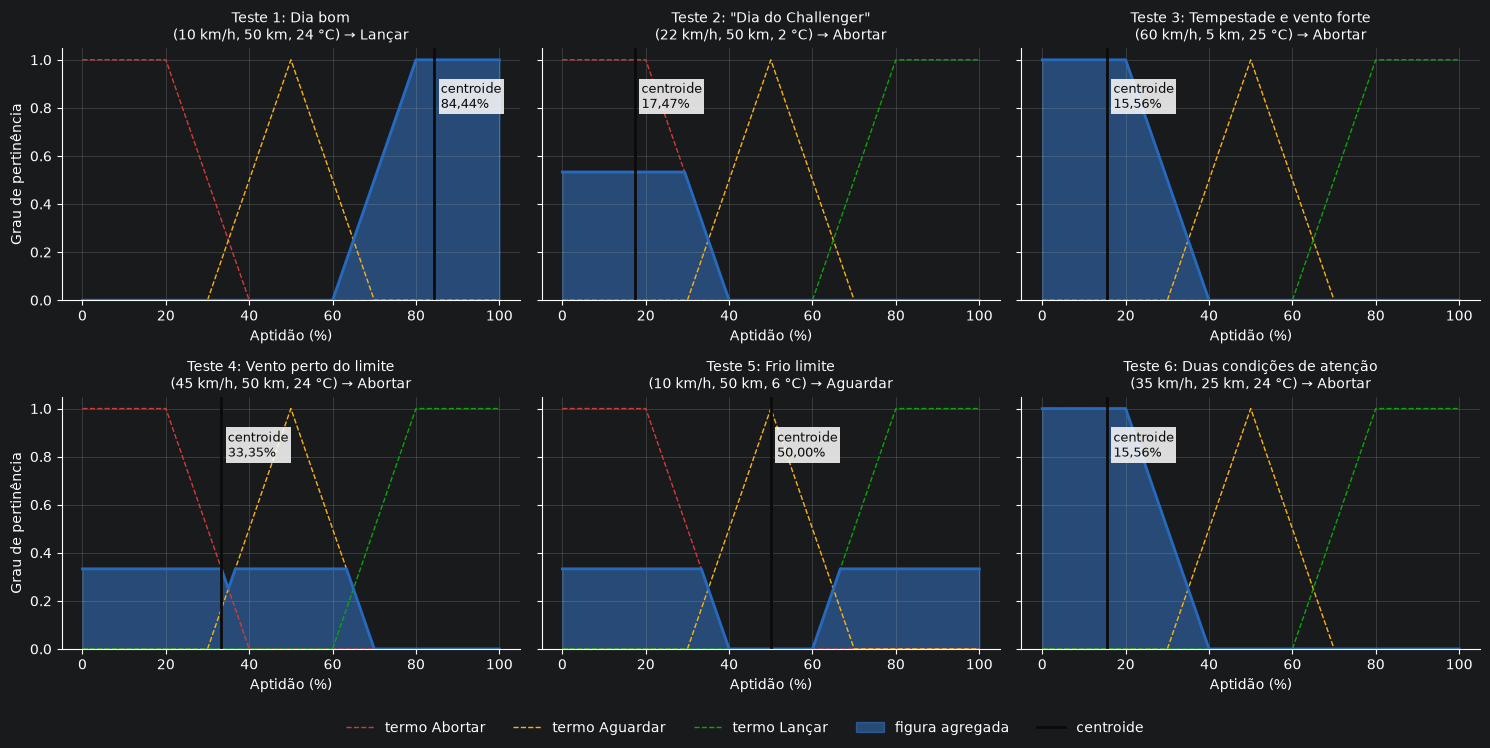

In [12]:
def figura_agregada(v, s, t):
    """Forma agregada calculada pelo próprio skfuzzy (a mesma que o método .view(sim=...) desenha)."""
    sim = ctrl.ControlSystemSimulation(sistema, clip_to_bounds=True)
    for nome, valor in zip(['vento', 'tempestade', 'temperatura'], (v, s, t)):
        sim.input[nome] = valor
    sim.compute()
    universo, agregada, _ = CrispValueCalculator(aptidao, sim).find_memberships()
    return universo, agregada, float(sim.output['aptidao'])

fig, eixos = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for ax, (_, linha) in zip(eixos.flat, tabela_testes.iterrows()):
    universo, agregada, saida = figura_agregada(linha['Vento (km/h)'], linha['Tempestade (km)'], linha['Temp. (°C)'])
    centroide = fuzz.defuzz(universo, agregada, 'centroid')
    assert abs(centroide - saida) < 1e-9 and abs(round(saida, 2) - linha['Obtido (%)']) < 1e-9
    for termo in aptidao.terms:
        ax.plot(aptidao.universe, aptidao[termo].mf, color=COR_SAIDA[termo], linestyle='--', linewidth=1, label=f'termo {termo}')
    ax.fill_between(universo, agregada, color='#3987e5', alpha=0.45, label='figura agregada')
    ax.plot(universo, agregada, color='#256abf', linewidth=2)
    ax.axvline(centroide, color=COR_TEXTO, linewidth=2, label='centroide')
    ax.text(centroide + 1.5, 0.80, f'centroide\n{centroide:.2f}%'.replace('.', ','), fontsize=9, color=COR_TEXTO,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.5))
    ax.set_title(f'Teste {linha["#"]}: {linha["Situação"]}\n'
                 f'({linha["Vento (km/h)"]} km/h, {linha["Tempestade (km)"]} km, {linha["Temp. (°C)"]} °C) → {linha["Leitura"]}', fontsize=10)
    ax.set_xlabel('Aptidão (%)')
    ax.set_ylim(0, 1.05)
eixos[0, 0].set_ylabel('Grau de pertinência')
eixos[1, 0].set_ylabel('Grau de pertinência')
fig.legend(*eixos[0, 0].get_legend_handles_labels(), loc='lower center', ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Interpretação dos gráficos.**

- **Teste 1:** a figura agregada é o trapézio inteiro de Lançar (força 1). O centroide em 84,44% é o maior valor que o sistema consegue dar.
- **Testes 3 e 6:** a figura é o trapézio inteiro de Abortar. O centroide em 15,56% é o menor valor possível.
- **Teste 2:** só Abortar aparece, mas cortado em 0,53. A parte plana vai até cerca de 29% (em vez de 20%), e por isso o centroide sobe para 17,47%, ainda bem dentro de Abortar.
- **Teste 4:** Abortar e Aguardar aparecem cortados na mesma altura (0,33). A figura é quase um "platô" de 0 a cerca de 63%, com uma pequena depressão perto de 35%. O centroide fica em 33,35%, logo abaixo da faixa de Aguardar.
- **Teste 5:** aparecem duas figuras separadas, Abortar à esquerda e Lançar à direita, as duas em 0,33. Não há nada no meio, mas o centro de gravidade das duas juntas cai em 50%. Isso mostra uma limitação conhecida do centroide: uma aptidão de 50% pode vir de "metade do caminho" (Aguardar) ou de uma mistura de "lançar" e "abortar".

## 9. Superfícies de saída e análise

As superfícies mostram a aptidão para todas as combinações de duas entradas, com a terceira fixa num valor favorável. Assim, o efeito do par aparece sem ser mascarado pela entrada fixa. Cada eixo tem 41 pontos, de ponta a ponta do domínio.

| # | Eixos | Entrada fixa | O que se espera ver |
| --- | --- | --- | --- |
| 1 | Vento × Tempestade | Temperatura = 20 °C | Platô alto só no canto vento fraco e tempestade longe. Queda rápida em torno de 45 km/h e 18 km. |
| 2 | Vento × Temperatura | Tempestade = 50 km | Platô alto em vento fraco e temperatura amena. "Penhascos" perto de 6 °C e de 45 km/h, e um degrau intermediário (Aguardar) no calor. |
| 3 | Tempestade × Temperatura | Vento = 10 km/h | Platô alto com tempestade longe e temperatura amena. Faixa de Aguardar com tempestade a média distância. |

A célula abaixo calcula as três grades com a função `avaliar_lote` (modo em lote, conferido na seção 7) e desenha as superfícies. A cor e a altura indicam a aptidão.

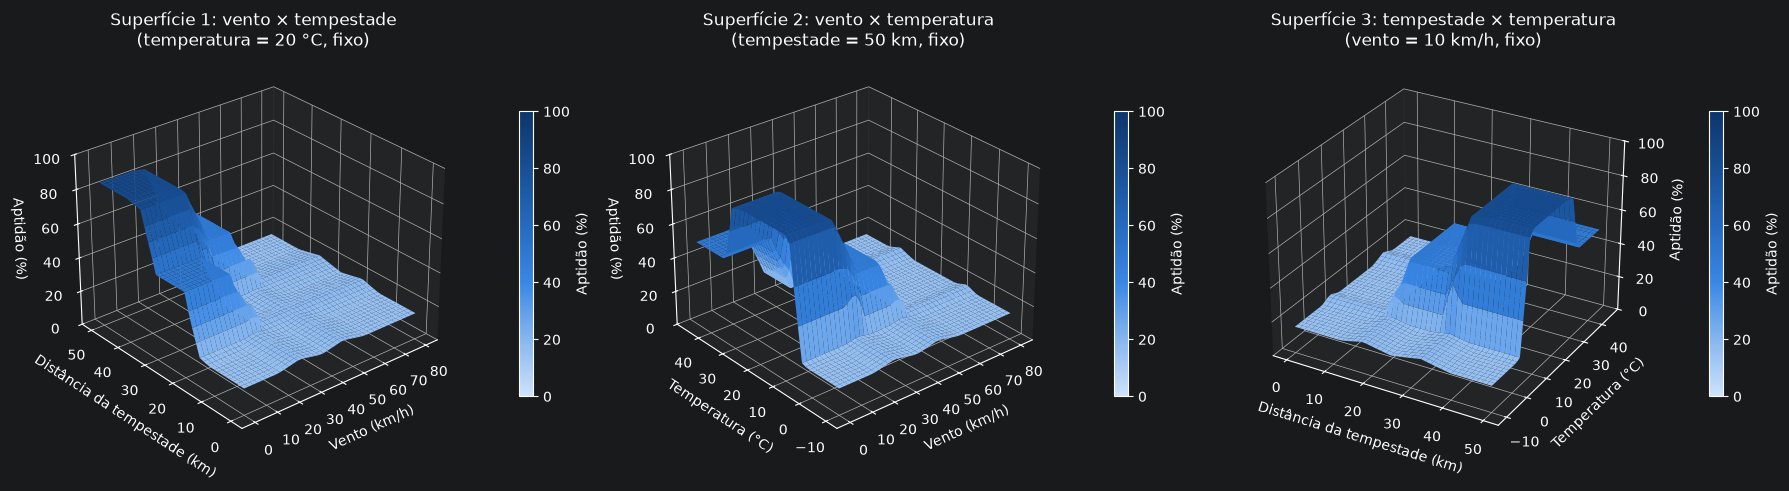

,Mín. (%),Máx. (%),% Abortar,% Aguardar,% Lançar,"% no teto (84,44)","% no piso (15,56)","% Abortar entre 15,56 e 20"
Superfície,,,,,,,,
1: vento × tempestade (temperatura = 20),15.56,84.44,71.33,17.31,11.36,4.28,20.23,45.27
2: vento × temperatura (tempestade = 50),15.56,84.44,65.44,20.76,13.80,5.71,25.94,34.80
3: tempestade × temperatura (vento = 10),15.56,84.44,61.27,22.84,15.88,6.42,22.43,34.03


In [13]:
FIXOS = {'vento': 10, 'tempestade': 50, 'temperatura': 20}
EIXOS = {'vento': np.linspace(0, 80, 41), 'tempestade': np.linspace(0, 50, 41), 'temperatura': np.linspace(-10, 45, 41)}
PARES = [('vento', 'tempestade', 'temperatura'), ('vento', 'temperatura', 'tempestade'), ('tempestade', 'temperatura', 'vento')]

def grade_superficie(eixo_x, eixo_y, fixo):
    X, Y = np.meshgrid(EIXOS[eixo_x], EIXOS[eixo_y])
    entradas = {eixo_x: X, eixo_y: Y, fixo: np.full_like(X, FIXOS[fixo])}
    Z = avaliar_lote(entradas['vento'], entradas['tempestade'], entradas['temperatura'])
    return X, Y, Z

superficies = {par: grade_superficie(*par) for par in PARES}

fig = plt.figure(figsize=(18, 6))
for k, (eixo_x, eixo_y, fixo) in enumerate(PARES, start=1):
    X, Y, Z = superficies[(eixo_x, eixo_y, fixo)]
    ax = fig.add_subplot(1, 3, k, projection='3d')
    sup = ax.plot_surface(X, Y, Z, cmap=MAPA_APTIDAO, vmin=0, vmax=100, linewidth=0, antialiased=True)
    fig.colorbar(sup, ax=ax, shrink=0.5, pad=0.12, label='Aptidão (%)')
    ax.set_xlabel(UNIDADES[eixo_x])
    ax.set_ylabel(UNIDADES[eixo_y])
    ax.set_zlabel('Aptidão (%)')
    ax.set_zlim(0, 100)
    ax.view_init(elev=28, azim=-130 if eixo_x == 'vento' else -60)
    unidade = UNIDADES[fixo].split('(')[1].rstrip(')')
    ax.set_title(f'Superfície {k}: {eixo_x} × {eixo_y}\n({fixo} = {FIXOS[fixo]} {unidade}, fixo)')
fig.tight_layout()
plt.show()

resumo = []
for k, par in enumerate(PARES, start=1):
    Z = superficies[par][2]
    classes = pd.Series([leitura(z) for z in Z.flat]).value_counts(normalize=True) * 100
    resumo.append({'Superfície': f'{k}: {par[0]} × {par[1]} ({par[2]} = {FIXOS[par[2]]})', 'Mín. (%)': Z.min(), 'Máx. (%)': Z.max(),
                   '% Abortar': classes.get('Abortar', 0), '% Aguardar': classes.get('Aguardar', 0), '% Lançar': classes.get('Lançar', 0),
                   '% no teto (84,44)': np.isclose(Z, Z.max()).mean() * 100, '% no piso (15,56)': np.isclose(Z, Z.min()).mean() * 100,
                   '% Abortar entre 15,56 e 20': ((Z > Z.min() + 1e-6) & (Z < 20)).mean() * 100})
pd.DataFrame(resumo).set_index('Superfície').round(2)

**Como ler as superfícies.** Os dois eixos do "chão" são as duas entradas que variam, e a altura (e a cor, do azul claro ao escuro) é a aptidão. A tabela abaixo dos gráficos dá, para cada superfície, o mínimo, o máximo e a fração da área lida como Abortar, Aguardar e Lançar.

**Regiões planas.** As três superfícies têm três **patamares** (regiões planas), ligados por **rampas** (regiões de transição): 84,44% (só a regra 1, Lançar, ativa com força 1), 50% (uma única regra de Aguardar ativa, pois o triângulo de Aguardar é simétrico em torno de 50) e 15,56% (só regras de Abortar ativas, a mais forte com força 1). Quando só há regras de Abortar ativas, mas a mais forte tem força menor que 1, o trapézio cortado fica mais largo e o centroide sobe um pouco, como no teste 2 (17,47%): por isso boa parte da região de Abortar fica entre 15,56% e 20%, e não exatamente no piso (coluna "% Abortar entre 15,56 e 20" da tabela). As rampas ficam nas faixas em que dois termos de uma entrada se sobrepõem. Nenhuma superfície passa de 84,44% nem desce abaixo de 15,56%, pelo limite do centroide.

**Superfície 1 (vento × tempestade, temperatura = 20 °C).** Como se esperava, o platô alto (84,44%) aparece só no canto de vento fraco (até 15 km/h) e tempestade longe (a partir de 40 km), e ocupa 4,28% da área; somando as rampas, a região lida como Lançar ocupa 11,36%. Há dois degraus de Aguardar (50%): vento entre 30 e 40 km/h com tempestade longe (regra 10) e tempestade entre 20 e 30 km com vento fraco (regra 4). Onde os dois se encontram (vento Moderado e tempestade Média), a superfície cai para Abortar pela regra 13: é a "vala" das duas condições de atenção. As quedas ficam em torno de 44 km/h e de 17,5–18 km (curvas 1D abaixo), perto do esperado (45 km/h e 18 km). Vento a partir de 55 km/h ou tempestade até 12 km levam a Abortar, qualquer que seja a outra entrada (perto do piso, mas não sempre exatamente 15,56%). Abortar ocupa 71,33% da área.

**Superfície 2 (vento × temperatura, tempestade = 50 km).** O platô alto fica em vento fraco e temperatura amena (10 a 26 °C) e ocupa 5,71% da área (13,80% somando as rampas lidas como Lançar). Os dois "penhascos" esperados aparecem: o do frio, entre 2 e 8 °C (com a troca de faixa perto de 6 °C), e o do vento, perto de 44 km/h. No calor, a partir de 33 °C com vento fraco, aparece o degrau intermediário de 50% (regra 2, Quente → Aguardar). Calor com vento moderado cai para Abortar (regra 11, duas condições de atenção). Já o frio (até 2 °C) leva a Abortar com qualquer vento (regras 3, 12 e 21). Quando o vento não pertence totalmente a nenhum termo (entre 15 e 55 km/h, exceto em 35 km/h, o pico do Moderado), a regra de Abortar mais forte tem força menor que 1, e o valor fica um pouco acima do piso, como no teste 2 (17,47%).

**Superfície 3 (tempestade × temperatura, vento = 10 km/h).** O platô alto fica com tempestade longe (a partir de 40 km) e temperatura amena e ocupa 6,42% da área (15,88% somando as rampas lidas como Lançar). A faixa de Aguardar esperada aparece com a tempestade a média distância (20 a 30 km) e temperatura amena (regra 4), e também com tempestade longe e calor (regra 2). Tempestade média com calor cai para Abortar (regra 5). É a superfície com mais Aguardar (22,84%) e menos Abortar (61,27%). O motivo está nos eixos que variam: o vento, a entrada com a maior faixa crítica (o termo Forte tem grau maior que zero de 40 a 80 km/h, metade do domínio), está fixo num valor favorável. A tempestade (Perto até 20 km, 40% do domínio) e a temperatura (Fria até 8 °C, cerca de 33% do domínio) têm faixas críticas menores, e a temperatura ainda tem o degrau largo de Aguardar no calor.

**Qual entrada derruba a aptidão mais rápido.** É a **temperatura, pelo lado do frio**: ela vai do teto ao piso em 8 °C (de 10 a 2 °C), só 14,5% do domínio, com inclinação máxima de 17,6 pontos por °C. A tempestade precisa de 28 km (56,0% do domínio) e o vento, de 40 km/h (50,0%). Os números saem da célula das curvas 1D, logo abaixo. Isso vem da forma das funções de pertinência: no lado frio, o termo favorável (Amena) encosta direto no crítico (Fria), sem nenhum termo de atenção no meio. No vento e na tempestade, o caminho do teto ao piso passa por uma rampa favorável, um patamar de Aguardar de 10 unidades (regras 10 e 4) e uma rampa crítica.

**Resultados inesperados e limitações.**

- **Achatamento:** de 61% a 71% da área de cada superfície é Abortar, reflexo das 23 regras de Abortar. A superfície é feita de patamares, com pouca graduação fora das zonas de sobreposição.
- **A vala das duas condições:** duas condições de atenção "leves" (por exemplo, vento de 35 km/h e tempestade a 25 km) dão uma aptidão menor que qualquer uma delas sozinha (50%). É coerente com a hipótese conservadora do modelo, mas cria uma queda abrupta (uma vala) no meio da superfície 1.
- **O degrau de calor é baixo e plano:** de 33 a 45 °C, a aptidão fica em 50% o tempo todo, porque Quente é só atenção. Um calor extremo nunca aborta sozinho, o que é uma hipótese declarada, e não um erro.

### Influência de cada entrada (curvas 1D)

Além das superfícies, é preciso demonstrar que as três entradas mudam a aptidão. A célula abaixo varia cada entrada sozinha, de ponta a ponta do domínio (passo de 0,5), com as outras duas nos mesmos valores favoráveis usados nas superfícies (vento 10 km/h, tempestade 50 km, temperatura 20 °C). Ela também imprime em que valor a leitura muda de faixa.

vento      : aptidão vai de 15.56% a 84.44%; do teto ao piso em 40 unidades (50.0% do domínio); maior inclinação 3.8 pontos por unidade, em 29.5
tempestade : aptidão vai de 15.56% a 84.44%; do teto ao piso em 28 unidades (56.0% do domínio); maior inclinação 8.0 pontos por unidade, em 19.5
temperatura: aptidão vai de 15.56% a 84.44%; do teto ao piso em 8 unidades (14.5% do domínio); maior inclinação 17.6 pontos por unidade, em 7.5


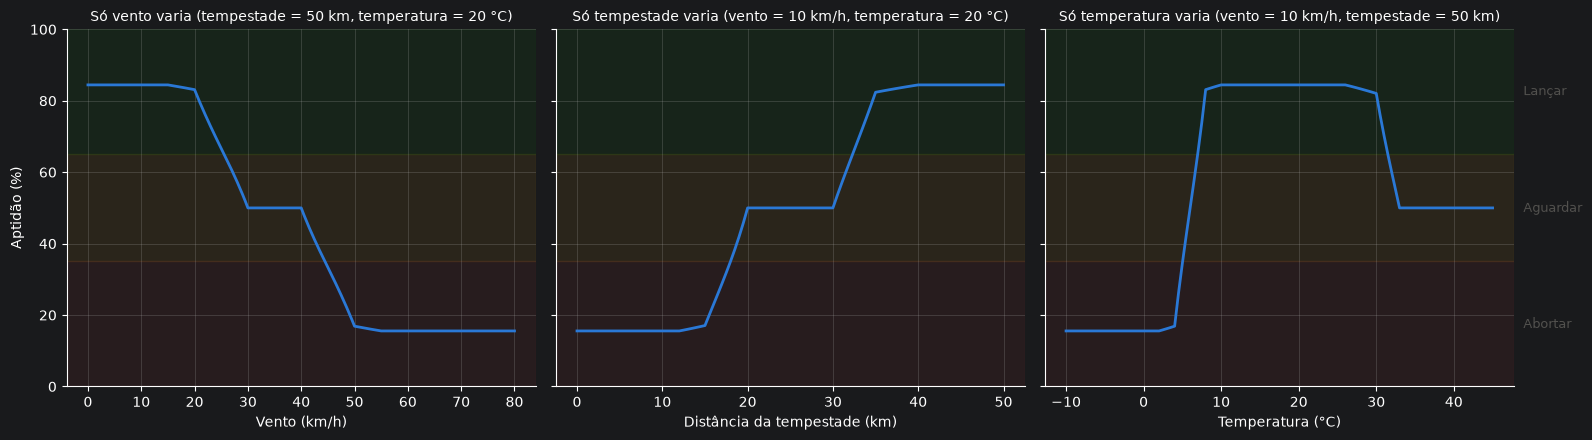

,Entrada,De,Para,Entre (valor),Aptidão antes (%),Aptidão depois (%)
0,vento,Lançar,Aguardar,25.5 e 26,65.14,63.62
1,vento,Aguardar,Abortar,44 e 44.5,36.38,34.86
2,tempestade,Abortar,Aguardar,17.5 e 18,31.89,35.05
3,tempestade,Aguardar,Lançar,32 e 32.5,63.10,66.23
4,temperatura,Abortar,Aguardar,5 e 5.5,34.52,42.38
5,temperatura,Aguardar,Lançar,6.5 e 7,57.62,65.48
6,temperatura,Lançar,Aguardar,31 e 31.5,70.27,64.93


In [14]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
mudancas = []
for ax, nome, var in zip(eixos, ['vento', 'tempestade', 'temperatura'], [vento, tempestade, temperatura]):
    xs = var.universe
    entradas = {**{k: np.full_like(xs, val, dtype=float) for k, val in FIXOS.items()}, nome: xs}
    ys = avaliar_lote(entradas['vento'], entradas['tempestade'], entradas['temperatura'])
    for faixa, (y0, y1) in {'Abortar': (0, 35), 'Aguardar': (35, 65), 'Lançar': (65, 100)}.items():
        ax.axhspan(y0, y1, color=COR_SAIDA[faixa], alpha=0.08)
        if nome == 'temperatura':
            ax.text(1.02, (y0 + y1) / 200, faixa, transform=ax.transAxes, va='center', fontsize=9, color='#52514e')
    ax.plot(xs, ys, color='#2a78d6')
    ax.set_xlabel(UNIDADES[nome])
    outros = ', '.join(f"{k} = {v} {UNIDADES[k].split('(')[1].rstrip(')')}" for k, v in FIXOS.items() if k != nome)
    ax.set_title(f'Só {nome} varia ({outros})', fontsize=10)
    ax.set_ylim(0, 100)
    leituras = [leitura(y) for y in ys]
    for i in range(1, len(xs)):
        if leituras[i] != leituras[i - 1]:
            mudancas.append({'Entrada': nome, 'De': leituras[i - 1], 'Para': leituras[i], 'Entre (valor)': f'{xs[i-1]:g} e {xs[i]:g}',
                             'Aptidão antes (%)': round(ys[i - 1], 2), 'Aptidão depois (%)': round(ys[i], 2)})
    x_topo, x_piso = xs[np.isclose(ys, ys.max())], xs[np.isclose(ys, ys.min())]
    largura = np.abs(x_topo[:, None] - x_piso[None, :]).min()
    inclinacao = np.abs(np.gradient(ys, xs))
    dominio = xs.max() - xs.min()
    print(f'{nome:11s}: aptidão vai de {ys.min():.2f}% a {ys.max():.2f}%; do teto ao piso em {largura:g} unidades '
          f'({largura / dominio * 100:.1f}% do domínio); maior inclinação {inclinacao.max():.1f} pontos por unidade, '
          f'em {xs[inclinacao.argmax()]:g}')
eixos[0].set_ylabel('Aptidão (%)')
fig.tight_layout()
plt.show()
pd.DataFrame(mudancas)

**Interpretação das curvas.** As três entradas, sozinhas, levam a aptidão do piso (15,56%) ao teto (84,44%), uma amplitude de 68,89 pontos. Isso demonstra que **todas as entradas têm influência efetiva na saída**, um dos requisitos do trabalho. A tabela acima mostra onde cada curva muda de faixa:

- **Vento:** Lançar → Aguardar entre 25,5 e 26 km/h, e Aguardar → Abortar entre 44 e 44,5 km/h. O sistema aborta cerca de 4 km/h antes do limite oficial de 48,3 km/h, porque em 44 km/h o termo Forte já tem grau 0,27 e puxa o centroide para baixo. O patamar de 50% entre 30 e 40 km/h é a regra 10 sozinha.
- **Tempestade:** Abortar → Aguardar entre 17,5 e 18 km, logo antes do limite de 18,5 km da regra de raios, e Aguardar → Lançar entre 32 e 32,5 km. O patamar de 50% entre 20 e 30 km é a regra 4 sozinha.
- **Temperatura:** Abortar → Aguardar entre 5 e 5,5 °C (o limite oficial é 4,4 °C) e Aguardar → Lançar entre 6,5 e 7 °C, o que mostra como o penhasco do frio é estreito. No calor, a aptidão sai de Lançar entre 31 e 31,5 °C (antes dos 35 °C oficiais, porque Quente começa em 30 °C) e fica parada em 50% a partir de 33 °C, sem nunca chegar a Abortar.

As inclinações estão em unidades diferentes (pontos por km/h, por km e por °C) e não se comparam diretamente. A comparação justa é pela fração do domínio que a queda ocupa: temperatura (frio) 14,5%, vento 50,0% e tempestade 56,0%. Por esse critério, o frio é de longe o mais abrupto, e o vento e a tempestade são parecidos.

## 10. Validação

A validação tem duas camadas. Elas vão além dos requisitos do trabalho e mostram se o sistema respeita os critérios reais.

### A) Comparação com o critério oficial (crisp)

O critério oficial é implementado como uma regra de sim/não: **não lança** se vento > 48,3 km/h, tempestade < 18,5 km, temperatura < 4,4 °C ou temperatura > 35 °C (limites lidos do CSV de critérios). O crisp e o fuzzy são rodados numa grade de 41 × 41 × 41 = 68.921 combinações de entradas, cobrindo os três domínios inteiros.

Regra de concordância:

- crisp "não" e fuzzy diferente de Lançar → concorda;
- crisp "sim" e fuzzy diferente de Abortar → concorda;
- os demais casos são divergências.

Além do percentual, a célula monta uma matriz de confusão (crisp sim/não × fuzzy Abortar/Aguardar/Lançar), porque Aguardar sempre conta como concordância e infla o percentual.

In [15]:
VENTO_MAX = criterios.loc[criterios.criterio.str.startswith('Máximo sustentado'), 'valor_convertido'].item()
TEMPESTADE_MIN = criterios.loc[criterios.variavel == 'tempestade', 'valor_convertido'].item()
TEMP_MIN = criterios.loc[criterios.criterio.str.startswith('Mínima para levar'), 'valor_convertido'].item()
TEMP_MAX = criterios.loc[criterios.criterio.str.startswith('Máxima para levar'), 'valor_convertido'].item()
print(f'Critério crisp: não lança se vento > {VENTO_MAX}, tempestade < {TEMPESTADE_MIN}, temperatura < {TEMP_MIN} ou > {TEMP_MAX}')

def crisp_lanca(v, s, t):
    return not (v > VENTO_MAX or s < TEMPESTADE_MIN or t < TEMP_MIN or t > TEMP_MAX)

inicio = time.perf_counter()
V, S, T = (a.ravel() for a in np.meshgrid(EIXOS['vento'], EIXOS['tempestade'], EIXOS['temperatura'], indexing='ij'))
grade = pd.DataFrame({'vento': V, 'tempestade': S, 'temperatura': T, 'aptidao': avaliar_lote(V, S, T)})
grade['fuzzy'] = grade.aptidao.map(leitura)
grade['crisp'] = ['sim' if crisp_lanca(v, s, t) else 'não' for v, s, t in zip(V, S, T)]
print(f'{len(grade)} combinações avaliadas em {time.perf_counter() - inicio:.0f} s '
      f'(41 pontos por eixo: vento a cada 2 km/h, tempestade a cada 1,25 km, temperatura a cada 1,375 °C).')

grade['concorda'] = ((grade.crisp == 'não') & (grade.fuzzy != 'Lançar')) | ((grade.crisp == 'sim') & (grade.fuzzy != 'Abortar'))
concordancia = grade.concorda.mean() * 100
print(f'Concordância: {concordancia:.2f}% ({grade.concorda.sum()} de {len(grade)}); divergências: {(~grade.concorda).sum()}')
por_classe = grade.groupby('crisp').concorda.mean() * 100
print(f'Concordância por classe do crisp: "sim" {por_classe["sim"]:.2f}%, "não" {por_classe["não"]:.2f}%; '
      f'média das duas (concordância balanceada): {por_classe.mean():.2f}%')
estrita = (((grade.crisp == 'não') & (grade.fuzzy == 'Abortar')) | ((grade.crisp == 'sim') & (grade.fuzzy == 'Lançar'))).mean() * 100
print(f'Concordância estrita (Aguardar não conta como acerto): {estrita:.2f}%')
print('Leitura fuzzy na grade (%):', (grade.fuzzy.value_counts(normalize=True) * 100).round(2).to_dict())
print('Leitura fuzzy quando o crisp diz "sim" (%):', (grade[grade.crisp == 'sim'].fuzzy.value_counts(normalize=True) * 100).round(2).to_dict())
print(f'Aptidão na grade: mínimo {grade.aptidao.min():.2f}%, máximo {grade.aptidao.max():.2f}%')
nao_aguardar = grade[(grade.crisp == 'não') & (grade.fuzzy == 'Aguardar')]
print(f'Crisp "não" e fuzzy Aguardar: {len(nao_aguardar)} pontos; com temperatura > {TEMP_MAX}: {(nao_aguardar.temperatura > TEMP_MAX).sum()} '
      f'(de {nao_aguardar.temperatura.min():g} a {nao_aguardar.temperatura.max():g} °C); '
      f'com outro limite violado: {((nao_aguardar.vento > VENTO_MAX) | (nao_aguardar.tempestade < TEMPESTADE_MIN) | (nao_aguardar.temperatura < TEMP_MIN)).sum()}')

matriz = pd.crosstab(grade.crisp, grade.fuzzy, margins=True, margins_name='Total').reindex(
    index=['sim', 'não', 'Total'], columns=['Abortar', 'Aguardar', 'Lançar', 'Total'])
matriz.index.name, matriz.columns.name = 'crisp (lança?)', 'fuzzy'
matriz

Critério crisp: não lança se vento > 48.3, tempestade < 18.5, temperatura < 4.4 ou > 35.0
68921 combinações avaliadas em 8 s (41 pontos por eixo: vento a cada 2 km/h, tempestade a cada 1,25 km, temperatura a cada 1,375 °C).
Concordância: 93.40% (64374 de 68921); divergências: 4547
Concordância por classe do crisp: "sim" 68.20%, "não" 100.00%; média das duas (concordância balanceada): 84.10%
Concordância estrita (Aguardar não conta como acerto): 82.04%
Leitura fuzzy na grade (%): {'Abortar': 83.74, 'Aguardar': 11.36, 'Lançar': 4.9}
Leitura fuzzy quando o crisp diz "sim" (%): {'Aguardar': 44.57, 'Abortar': 31.8, 'Lançar': 23.63}
Aptidão na grade: mínimo 15.56%, máximo 84.44%
Crisp "não" e fuzzy Aguardar: 1456 pontos; com temperatura > 35.0: 1456 (de 35.375 a 45 °C); com outro limite violado: 0


fuzzy,Abortar,Aguardar,Lançar,Total
crisp (lança?),,,,
sim,4547,6374,3379,14300
não,53165,1456,0,54621
Total,57712,7830,3379,68921


**Resultado.** A concordância é de **93,40%** (64.374 das 68.921 combinações). As 4.547 divergências são todas do tipo "crisp sim, fuzzy Abortar". **Não há nenhum ponto em que o fuzzy diga Lançar e o critério oficial proíba o lançamento** (coluna Lançar, linha "não" = 0). Do ponto de vista da segurança, essa é a divergência que importa, e ela não acontece.

**Matriz de confusão.**

- Quando o crisp diz **"não"** (54.621 pontos, 79% da grade, porque a grade cobre domínios inteiros e a maioria das combinações viola algum limite), o fuzzy dá Abortar em 53.165 e Aguardar em 1.456 pontos. Todos esses 1.456 Aguardar são de calor acima de 35 °C (de 35,375 a 45 °C), sem nenhum outro limite violado: o modelo trata o calor como atenção (regra 2), e não como crítico, mesmo em 45 °C. É o degrau de calor já visto na superfície 2.
- Quando o crisp diz **"sim"** (14.300 pontos), o fuzzy se divide em Aguardar (44,57%), Abortar (31,80%) e Lançar (23,63%). O fuzzy só "autoriza" plenamente um quarto das combinações que o critério oficial aceita: ele é mais exigente.
- **Concordância por classe:** o percentual global depende de quantos pontos da grade o crisp proíbe, e essa proporção (79%) vem da extensão dos domínios e da posição dos limites dentro deles. Por isso vale olhar cada classe: quando o crisp diz "não", o fuzzy concorda em 100% dos pontos (contando Aguardar como concordância, como no percentual global); quando diz "sim", em 68,20%. A média das duas (concordância balanceada) é de 84,10%.
- **Inflação pelo Aguardar:** Aguardar sempre conta como concordância. Se ele não contasse (concordância estrita: só "não × Abortar" e "sim × Lançar"), o percentual cairia para **82,04%**. A diferença (cerca de 11 pontos) corresponde aos 7.830 pontos de Aguardar (11,36% da grade).
- Na grade inteira, o fuzzy lê 83,74% dos pontos como Abortar, 11,36% como Aguardar e 4,90% como Lançar. A aptidão fica entre 15,56% e 84,44%, confirmando o limite do centroide.

O gráfico abaixo mostra onde ficam as divergências. À esquerda, todos os pontos divergentes no espaço das três entradas, separados pelo tipo. À direita, a contagem de divergências de cada tipo. Em seguida, a célula classifica cada divergência pela presença de um termo crítico com grau maior que zero e pelo número de termos de atenção com grau maior que zero, para separar as causas.

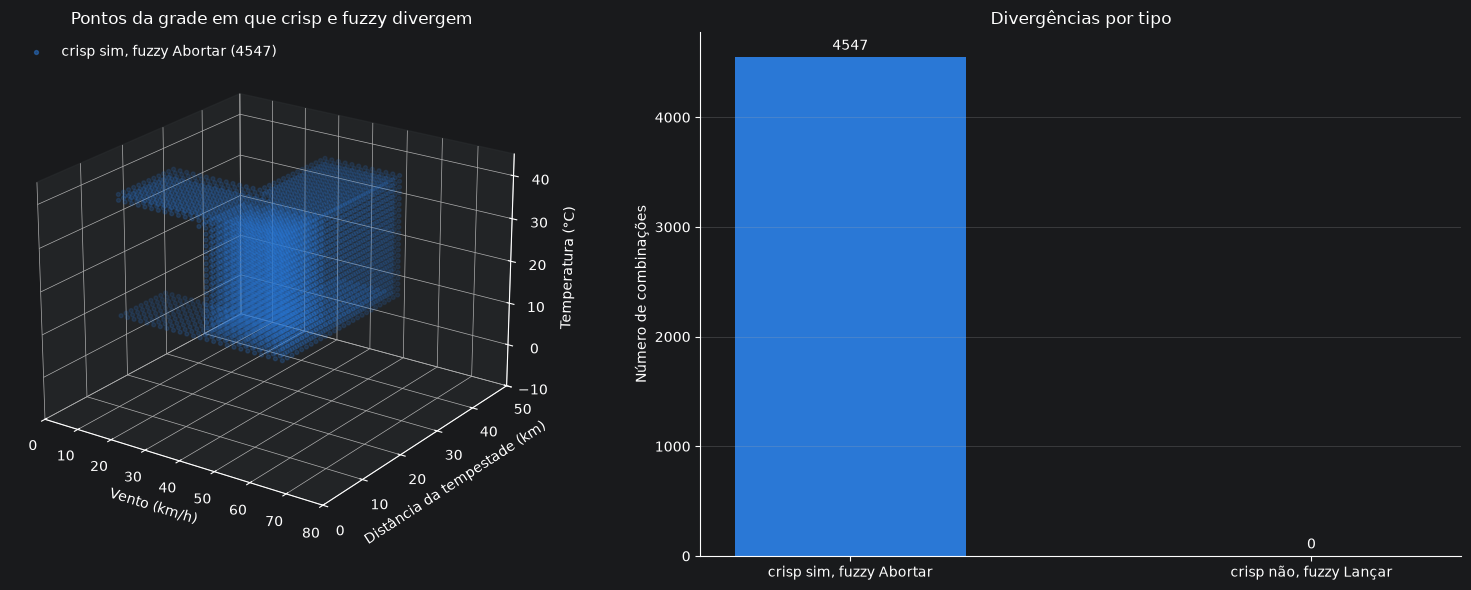

só a regra das duas condições de atenção (sem termo crítico): 2108 (46.4%)
só a rampa de um termo crítico (com uma única condição de atenção): 708 (15.6%)
as duas causas juntas (termo crítico > 0 e duas ou mais condições de atenção): 1731 (38.1%)
Divergências com duas ou mais condições de atenção (com ou sem termo crítico): 3839 (84.4%)
  - com vento entre 40 e 48,3 km/h: 1770
  - com temperatura entre 4,4 e 8 °C: 746
  - com tempestade entre 18,5 e 20 km: 304


nº de termos de atenção > 0,1,2,3,Total
termo crítico > 0,,,,
False,0,1783,325,2108
True,708,1547,184,2439
Total,708,3330,509,4547


In [16]:
divergentes = grade[~grade.concorda].copy()
divergentes['tipo'] = np.where(divergentes.crisp == 'sim', 'crisp sim, fuzzy Abortar', 'crisp não, fuzzy Lançar')
TIPOS = {'crisp sim, fuzzy Abortar': '#2a78d6', 'crisp não, fuzzy Lançar': '#eb6834'}

fig = plt.figure(figsize=(16, 6))
ax = fig.add_subplot(1, 2, 1, projection='3d')
for tipo, cor in TIPOS.items():
    sel = divergentes[divergentes.tipo == tipo]
    if len(sel):
        ax.scatter(sel.vento, sel.tempestade, sel.temperatura, s=8, color=cor, alpha=0.5, label=f'{tipo} ({len(sel)})')
ax.set_xlabel(UNIDADES['vento']); ax.set_ylabel(UNIDADES['tempestade']); ax.set_zlabel(UNIDADES['temperatura'])
ax.set_xlim(0, 80); ax.set_ylim(0, 50); ax.set_zlim(-10, 45)
ax.view_init(elev=22, azim=-55)
ax.set_title('Pontos da grade em que crisp e fuzzy divergem')
ax.legend(loc='upper left', frameon=False)

ax2 = fig.add_subplot(1, 2, 2)
contagem = divergentes.tipo.value_counts().reindex(list(TIPOS), fill_value=0)
barras = ax2.bar(contagem.index, contagem.values, color=[TIPOS[t] for t in contagem.index], width=0.5)
ax2.bar_label(barras, padding=3)
ax2.set_ylabel('Número de combinações')
ax2.set_title('Divergências por tipo')
ax2.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

# Onde estão as divergências "crisp sim, fuzzy Abortar": quantas condições de atenção do fuzzy aparecem em cada ponto
def n_termos_atencao(r):
    graus = [fuzz.interp_membership(vento.universe, vento['Moderado'].mf, r.vento),
             fuzz.interp_membership(tempestade.universe, tempestade['Média'].mf, r.tempestade),
             fuzz.interp_membership(temperatura.universe, temperatura['Quente'].mf, r.temperatura)]
    return sum(g > 0 for g in graus)

def tem_critico(r):
    graus = [fuzz.interp_membership(vento.universe, vento['Forte'].mf, r.vento),
             fuzz.interp_membership(tempestade.universe, tempestade['Perto'].mf, r.tempestade),
             fuzz.interp_membership(temperatura.universe, temperatura['Fria'].mf, r.temperatura)]
    return any(g > 0 for g in graus)

sim_abortar = divergentes[divergentes.crisp == 'sim'].copy()
sim_abortar['termo crítico > 0'] = sim_abortar.apply(tem_critico, axis=1)
sim_abortar['nº de termos de atenção > 0'] = sim_abortar.apply(n_termos_atencao, axis=1)
origem = pd.crosstab(sim_abortar['termo crítico > 0'], sim_abortar['nº de termos de atenção > 0'], margins=True, margins_name='Total')
critico = sim_abortar['termo crítico > 0']
duas_ou_mais = sim_abortar['nº de termos de atenção > 0'] >= 2
total_div = len(sim_abortar)
for rotulo, mascara in [('só a regra das duas condições de atenção (sem termo crítico)', ~critico & duas_ou_mais),
                        ('só a rampa de um termo crítico (com uma única condição de atenção)', critico & ~duas_ou_mais),
                        ('as duas causas juntas (termo crítico > 0 e duas ou mais condições de atenção)', critico & duas_ou_mais)]:
    print(f'{rotulo}: {mascara.sum()} ({mascara.sum() / total_div * 100:.1f}%)')
assert (~critico & ~duas_ou_mais).sum() == 0
print(f'Divergências com duas ou mais condições de atenção (com ou sem termo crítico): {duas_ou_mais.sum()} ({duas_ou_mais.mean() * 100:.1f}%)')
na_rampa = sim_abortar[sim_abortar['termo crítico > 0']]
print('  - com vento entre 40 e 48,3 km/h:', ((na_rampa.vento > 40) & (na_rampa.vento <= VENTO_MAX)).sum())
print('  - com temperatura entre 4,4 e 8 °C:', ((na_rampa.temperatura >= TEMP_MIN) & (na_rampa.temperatura < 8)).sum())
print('  - com tempestade entre 18,5 e 20 km:', ((na_rampa.tempestade >= TEMPESTADE_MIN) & (na_rampa.tempestade < 20)).sum())
origem

**Onde ficam as divergências.** No gráfico 3D, os pontos divergentes formam blocos dentro da região que o critério oficial aceita (vento até 48,3 km/h, tempestade a partir de 18,5 km, temperatura entre 4,4 e 35 °C). O gráfico de barras confirma que só existe um tipo de divergência. A tabela cruzada separa as 4.547 divergências pela causa:

- **2.108 (46,4%) vêm só da regra das duas condições de atenção, sem nenhum termo crítico ativo.** É a divergência que já se esperava: ali o fuzzy é mais conservador de propósito (regras 5, 11, 13 e 14).
- **708 (15,6%) vêm só da rampa de um termo crítico**, com uma única condição de atenção. Essa parte não era esperada. São pontos entre o limite oficial e o fim da rampa do termo crítico: vento acima de 40 km/h (o Forte começa em 40, antes dos 48,3 km/h), temperatura abaixo de 8 °C (a Fria vai até 8, acima dos 4,4 °C) ou tempestade abaixo de 20 km (a Perto vai até 20, além dos 18,5 km). Nessas faixas, um grau pequeno de termo crítico ativa uma regra de Abortar e puxa o centroide para baixo de 35%.
- **1.731 (38,1%) têm as duas causas ao mesmo tempo**: um termo crítico com grau maior que zero e duas ou mais condições de atenção.

Entre os pontos com termo crítico ativo (708 + 1.731 = 2.439), as contagens por faixa (1.770 no vento, 746 na temperatura e 304 na tempestade) somam mais que 2.439, porque um ponto pode estar em mais de uma faixa ao mesmo tempo.

**Interpretação.** O fuzzy concorda com o critério oficial nas regiões claras e dá Aguardar perto de vários limites, como esperado. A regra das duas condições de atenção, que já se esperava, está presente em 84,4% das divergências (2.108 + 1.731 de 4.547). Mas as funções de pertinência dos termos críticos, que começam um pouco antes dos limites oficiais, também contribuem: são a única causa em 15,6% dos casos e aparecem junto com a outra em 38,1%. As duas coisas formam uma "margem de segurança" em torno do critério crisp. Os parâmetros não foram alterados: se a intenção fosse coincidir mais com o crisp, as rampas de Forte, Fria e Perto teriam de começar exatamente nos limites oficiais, o que mudaria os pontos definidos na modelagem.

### B) Estudos de caso reais

Os três casos são lidos do CSV `casos_reais.csv`. O vento de entrada é o ponto médio entre `vento_kmh_min` e `vento_kmh_max`; a rajada fica só como registro. A aptidão do sistema é comparada, de forma aproximada, com **100% menos a probabilidade oficial de violação** dos critérios, extraída da coluna `referencia_real`. O Challenger não tem probabilidade (é uma medição do dia do acidente, não uma previsão), então a comparação dele é qualitativa. A célula também recalcula o dia ruim com a tempestade no limite de 18,5 km, para mostrar o efeito da estimativa da distância.

In [17]:
ESPERADO_CASOS = {'Challenger': 'Abortar', 'Dia bom': 'Lançar', 'Dia ruim': 'Abortar'}

linhas_b = []
for _, c in casos.iterrows():
    v = (c.vento_kmh_min + c.vento_kmh_max) / 2
    apt, ativas = avaliar(v, c.dist_tempestade_km, c.temp_c, com_regras=True)
    prob = re.search(r'(\d+(?:[.,]\d+)?)\s*%', c.referencia_real)
    referencia = 100 - float(prob.group(1).replace(',', '.')) if prob else np.nan
    linhas_b.append({'Caso': c.caso, 'Vento usado (km/h)': v, 'Rajada (só registro)': c.rajada_kmh,
                     'Tempestade (km)': c.dist_tempestade_km, 'Temp. (°C)': c.temp_c,
                     'Aptidão fuzzy (%)': round(apt, 2), 'Leitura': leitura(apt), 'Esperado': ESPERADO_CASOS[c.caso],
                     'Referência real': c.referencia_real, '100% − P(violação)': referencia,
                     'Diferença (pontos)': round(apt - referencia, 2) if prob else np.nan,
                     'Regras ativadas (força)': descreve_regras(ativas)})
tabela_casos = pd.DataFrame(linhas_b).set_index('Caso')
assert (tabela_casos['Leitura'] == tabela_casos['Esperado']).all(), 'Algum caso real não deu a leitura esperada'

# Sensibilidade do dia ruim à distância estimada ('até 10 milhas náuticas' = de 0 a 18,5 km)
ruim = casos.set_index('caso').loc['Dia ruim']
for distancia in (ruim.dist_tempestade_km, 18.5):
    apt = avaliar((ruim.vento_kmh_min + ruim.vento_kmh_max) / 2, distancia, ruim.temp_c)
    print(f'Dia ruim com a tempestade a {distancia} km: aptidão {apt:.2f}% ({leitura(apt)})')
tabela_casos

Dia ruim com a tempestade a 9.3 km: aptidão 17.56% (Abortar)
Dia ruim com a tempestade a 18.5 km: aptidão 38.39% (Aguardar)


,Vento usado (km/h),Rajada (só registro),Tempestade (km),Temp. (°C),Aptidão fuzzy (%),Leitura,Esperado,Referência real,100% − P(violação),Diferença (pontos),Regras ativadas (força)
Caso,,,,,,,,,,,
Challenger,22.0,NaN,50.0,2.2,17.47,Abortar,Abortar,Lançou; desintegrou-se aos 73 s,NaN,NaN,R3 Fraco/Longe/Fria→Abortar (0.53); R12 Moderado/Longe/Fria→Abortar (0.13)
Dia bom,4.0,NaN,50.0,18.3,84.44,Lançar,Lançar,5% de chance de violar os critérios,95.0,-10.56,R1 Fraco/Longe/Amena→Lançar (1.00)
Dia ruim,18.5,NaN,9.3,29.4,17.56,Abortar,Abortar,60% de chance de violar os critérios,40.0,-22.44,R7 Fraco/Perto/Amena→Abortar (0.51)


**Interpretação dos casos reais.** Nos três casos, a leitura do sistema é a esperada.

- **Challenger (1986):** aptidão de **17,47%**, Abortar. O sistema teria recomendado não lançar. Os 2,2 °C são 0,97 Fria. A força das regras 3 (0,53) e 12 (0,13) fica limitada pelo grau do vento (0,53 Fraco e 0,13 Moderado), porque o "E" usa o mínimo, mas todas as regras ativas são de Abortar. O resultado é idêntico ao do teste 2, porque com tempestade Longe (grau 1) a temperatura de 2 °C ou 2,2 °C só muda o grau de Fria, que continua acima do grau do vento. Não há probabilidade oficial para comparar: a referência real é que o ônibus espacial lançou e se desintegrou aos 73 s. A comparação é qualitativa, e o sistema está do lado certo.
- **Dia bom (Crew-6, 2023):** aptidão de **84,44%**, Lançar. O vento de 4 km/h (ponto médio de "calmo a 5 mph") é Fraco com grau 1, não há tempestade e os 18,3 °C são Amena com grau 1, então só a regra 1 ativa, com força 1. É o maior valor que o sistema consegue dar. A referência (100% − 5% = 95%) fica 10,56 pontos acima, e essa diferença vem toda do teto do centroide (84,44%). Na previsão oficial, a principal preocupação era a regra de nuvens cumulus, que o modelo não tem.
- **Dia ruim (Atlas AC-167, 2004):** aptidão de **17,56%**, Abortar. A tempestade estimada em 9,3 km é Perto com grau 1, uma condição crítica. O vento de 18,5 km/h é 0,77 Fraco, e os 29,4 °C são 0,51 Amena (já na descida para o calor), então só a regra 7 (Fraco/Perto/Amena → Abortar) ativa, com força 0,51. A referência é 100% − 60% = 40%, e o sistema fica 22,44 pontos abaixo. A causa é a estimativa da distância: a previsão dizia apenas que poderia haver tempestades isoladas a até 10 milhas náuticas, e o ponto médio coloca a tempestade totalmente Perto, o que faz o sistema abortar com segurança. A célula acima mostra a sensibilidade: com a tempestade no limite de 18,5 km, já na transição Perto/Média, a aptidão sobe para 38,39%, lida como Aguardar, perto dos 40% da referência.

A comparação com "100% − probabilidade" é aproximada: a probabilidade oficial inclui regras de nuvens e de vento em altitude que o modelo não tem, e a aptidão fuzzy não é uma probabilidade.

## 11. Conclusões

O sistema Mamdani com 3 entradas, 1 saída e 27 regras cumpre os requisitos do trabalho: cobre todo o domínio (verificado no código), usa uma base completa e coerente (as 27 regras geradas pela lógica crítico/atenção são idênticas às da tabela de conferência), e as três entradas têm influência efetiva (cada uma, sozinha, leva a aptidão de 15,56% a 84,44%). Nos seis testes, as regras ativadas são exatamente as previstas, e cinco dão a leitura esperada. Os três casos reais dão a leitura esperada. Na validação A, a concordância com o critério oficial é de 93,40% (82,04% no sentido estrito), e o fuzzy **nunca** recomenda Lançar onde o critério oficial proíbe.

### O que realmente apareceu

- **Teste 4 (vento de 45 km/h):** 33,35%, lido como Abortar, embora o esperado fosse "entre Aguardar e Abortar". O valor está mesmo entre os dois termos, mas o centroide é puxado para o lado de Abortar: o centro do pedaço cortado de Abortar (cerca de 18%) fica mais longe do limiar de 35% que o de Aguardar (50%), e o pedaço de Abortar tem um pouco mais de área. Nenhum parâmetro foi alterado para levá-lo a Aguardar.
- **Teste 5 (6 °C):** 50% exatos sem nenhuma regra de Aguardar ativa, como previsto. É um bom exemplo de que o valor do centroide sozinho esconde se o sistema está "em dúvida" ou "dividido entre extremos".
- **Divergências da validação A:** esperavam-se divergências só na zona das duas condições de atenção. Essa zona é a única causa em 46,4% delas e aparece junto com a rampa de um termo crítico em outros 38,1%. Os 15,6% restantes vêm só das rampas dos termos críticos (Forte, Fria, Perto), que começam antes dos limites oficiais e tornam o fuzzy mais conservador perto deles.
- **Casos reais:** o sistema acerta a decisão nos três, mas a escala da aptidão não é comparável a uma probabilidade. No dia bom, dá o máximo possível (84,44%), 10,56 pontos abaixo dos 95% da referência, por causa do teto do centroide. No dia ruim, dá 17,56% contra 40%, porque a distância da tempestade foi estimada pelo ponto médio de "até 10 milhas náuticas", o que a deixa totalmente Perto.

### Problemas enfrentados e soluções

- **Dependências do scikit-fuzzy:** a versão 0.5.0 usa scipy e networkx, mas não os instala sozinha. Os dois foram instalados e fixados no `requirements.txt` da raiz do repositório, além dos cinco pacotes principais.
- **Lentidão da avaliação ponto a ponto:** cada avaliação isolada leva dezenas de milissegundos, e a grade de 41³ levaria dezenas de minutos. A solução foi usar o modo vetorizado do próprio scikit-fuzzy (`avaliar_lote`), conferido contra a avaliação ponto a ponto em 200 entradas sorteadas (diferença zero). Assim a grade de 41 pontos por eixo pôde ser mantida, sem precisar cair para 21.
- **Força das regras apagada:** com o cache desligado (ou a cada 1.000 cálculos com o cache ligado), o scikit-fuzzy apaga as forças das regras. Para os testes e os casos reais, cada avaliação detalhada usa uma simulação nova.
- **Figura agregada:** reconstruir a agregação no universo de passo 1 dava um centroide com diferença de cerca de 0,01 ponto em relação ao motor, porque o scikit-fuzzy acrescenta os pontos exatos dos cortes. A figura passou a ser obtida do próprio motor, e o centroide bate exatamente.

### Limitações

- **Só três fatores do clima** (sem nuvens, chuva e vento em altitude). Isso explica parte da diferença com as previsões reais da validação B, que incluem essas regras.
- **Limites de foguetes diferentes misturados num modelo só** (Falcon 9, Atlas V, Artemis I, ônibus espacial). O sistema não representa nenhum foguete real em particular.
- **Vento medido em alturas diferentes e rajadas ignoradas.** O vento do Challenger foi medido a 60 pés, o critério do Falcon 9 vale a 162 pés, e as previsões dos casos reais não informam a altura nem as rajadas.
- **Base conservadora, com 23 das 27 regras em Abortar.** Ela gera superfícies "achatadas" (61% a 71% da área em Abortar, com o platô de Lançar ocupando só 4% a 6%), a "vala" das duas condições de atenção e 83,74% da grade lida como Abortar.
- **Saída presa entre 15,56% e 84,44% pelo centroide**, confirmada nos testes, nas superfícies e na grade. Uma aptidão de 100% (ou de 0%) nunca aparece.
- **Poucos casos reais, e com dados estimados.** São só três casos. A distância da tempestade do dia ruim é uma estimativa (ponto médio de 0 a 10 milhas náuticas), o dia bom junta duas fontes (a probabilidade da NASA e o vento e a temperatura da FOX 35), os dois casos são previsões, e não medições, e o Challenger não tem probabilidade para comparar.

### Observações

Os valores esperados eram hipóteses, e os resultados foram registrados como saíram do código, sem ajuste de parâmetros. Se a postura conservadora fosse considerada excessiva, o ajuste natural seria passar a regra das duas condições de atenção de Abortar para Aguardar. Pelos resultados acima, outra opção seria alinhar o início das rampas dos termos críticos aos limites oficiais.

## 12. Referências

CAWLEY, J. *Weather looking great for NASA’s SpaceX Crew-6 launch*. NASA Commercial Crew Program Blog, Kennedy Space Center, 27 fev. 2023. Disponível em: <https://www.nasa.gov/blogs/commercialcrew/2023/02/27/weather-looking-great-for-nasas-spacex-crew-6-launch/>. Acesso em: 7 nov. 2026.

FOX 35 ORLANDO. *Crew-6 launch forecast: will Florida skies stay clear for liftoff?* Orlando, 25 fev. 2023. Disponível em: <https://www.fox35orlando.com/news/crew-6-launch-forecast-will-florida-skies-stay-clear-for-liftoff>. Acesso em: 7 nov. 2026.

JASPER, G. L. *et al*. *Atmospheric environment for Space Shuttle (STS-51L) launch*. Huntsville: NASA Marshall Space Flight Center, 1986. (NASA Technical Memorandum, 86577). Disponível em: <https://ntrs.nasa.gov/citations/19870009517>. Acesso em: 7 nov. 2026.

MAMDANI, E. H.; ASSILIAN, S. An experiment in linguistic synthesis with a fuzzy logic controller. *International Journal of Man-Machine Studies*, v. 7, n. 1, p. 1–13, 1975. DOI: [10.1016/S0020-7373(75)80002-2](<https://doi.org/10.1016/S0020-7373(75)80002-2>).

NASA. *Artemis I weather criteria*. Washington, DC: NASA, [2022?]. Disponível em: <https://www.nasa.gov/directorates/esdmd/common-exploration-systems-development-division/orion-program/artemis-i-weather-criteria/>. Acesso em: 7 nov. 2026.

NASA. *Falcon 9 Crew Dragon launch weather criteria*. Kennedy Space Center: NASA, 2020. (NASA Facts, FS-2020-05-568-KSC). Disponível em: <https://www.nasa.gov/wp-content/uploads/2021/07/falcon9_crewdragon_launch_weather_criteria_fact_sheet.pdf>. Acesso em: 7 nov. 2026.

NASA. *Space Shuttle weather launch commit criteria*. Kennedy Space Center: NASA, mar. 2011. Disponível em: <https://www3.nasa.gov/centers/kennedy/pdf/633165main_weather-rules-march2011.pdf>. Acesso em: 7 nov. 2026.

PRESIDENTIAL COMMISSION ON THE SPACE SHUTTLE CHALLENGER ACCIDENT. *Report of the Presidential Commission on the Space Shuttle Challenger Accident*. Washington, DC, 1986. v. 1, cap. 3. Disponível em: <https://www.nasa.gov/history/rogersrep/v1ch3.htm>. Acesso em: 7 nov. 2026.

ROCKETLAUNCH.LIVE. *Launch scrub & delay statistics*. [S. l.], 2026. Disponível em: <https://www.rocketlaunch.live/scrub-statistics>. Acesso em: 7 nov. 2026.

ROSS, T. J. *Fuzzy logic with engineering applications*. 4. ed. Chichester: Wiley, 2016.

SCIKIT-FUZZY DEVELOPMENT TEAM. *scikit-fuzzy documentation*. Versão 0.5.0. [S. l.], 2024. Disponível em: <https://scikit-fuzzy.readthedocs.io>. Acesso em: 7 nov. 2026.

SPACEFLIGHT NOW. *Launch commit criteria for first Atlas 5*. [S. l.], 18 ago. 2002. Disponível em: <https://spaceflightnow.com/atlas/av001/020817weather/>. Acesso em: 7 nov. 2026.

SPACEFLIGHT NOW. *Launch weather forecast* [Atlas 2AS AC-167]. [S. l.], 29 ago. 2004. Disponível em: <https://spaceflightnow.com/atlas/ac167/040829wx.html>. Acesso em: 7 nov. 2026.

TAKAGI, T.; SUGENO, M. Fuzzy identification of systems and its applications to modeling and control. *IEEE Transactions on Systems, Man, and Cybernetics*, v. SMC-15, n. 1, p. 116–132, 1985. DOI: [10.1109/TSMC.1985.6313399](https://doi.org/10.1109/TSMC.1985.6313399).

ZADEH, L. A. Fuzzy sets. *Information and Control*, v. 8, n. 3, p. 338–353, 1965. DOI: [10.1016/S0019-9958(65)90241-X](<https://doi.org/10.1016/S0019-9958(65)90241-X>).